# Initalize libraries

## Import libraries

In [1]:
# general
import sys, os
import time
from os.path import join
from os import path
from importlib import reload
from getpass import getuser
from glob import glob
from tqdm.auto import tqdm
from multiprocessing import Pool
import json
import shutil 
import gc

# Data
import xarray as xr
import h5py
import numpy as np
import imageio
from nexusformat.nexus import *
from PIL import Image

# Plotting
import matplotlib.pyplot as plt

# skimage
import skimage.morphology
from skimage.draw import ellipse

# scipy
from scipy.ndimage import gaussian_filter
from scipy import stats
import scipy
from scipy.interpolate import griddata

# pyFAI
import pyFAI
from pyFAI.azimuthalIntegrator import AzimuthalIntegrator
from pyFAI.detectors import Detector

# Self-written libraries
sys.path.append(join(os.getcwd(), "library"))
import fthcore as fth
import helper_functions as helper
import mask_lib
import interactive
from interactive import cimshow
import reconstruct_rb as rec
import reconstruct as reco

plt.rcParams["figure.constrained_layout.use"] = True  # replaces plt.tight_layout

  File "/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/lib/python3.11/runpy.py", line 198, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/lib/python3.11/runpy.py", line 88, in _run_code
    exec(code, run_globals)
  File "/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/lib/python3.11/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/lib/python3.11/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start()
  File "/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 758, in start
    self.io_loop.start()
  File "/asap3/petra3/gpfs/p04/2025/data/11022988/shared/venv/lib/python3.11/site-packages/tornado/platform/asyncio.py", line 211, in start
    self.asyncio_loop.run_forever()
  File "/asap3/petra3

In [2]:
# Is there a GPU?
try:
    # Cupy
    import cupy as cp
    import cupyx as cpx

    GPU = True

    print("GPU available")

    # Self-written library
    import CCI_core_cupy as cci
    import Phase_Retrieval as PhR
except:
    GPU = False
    import CCI_core as cci

    print("GPU unavailable")

GPU available


In [3]:
# interactive plotting
import ipywidgets

%matplotlib widget

# Auto formatting of cells
#%load_ext jupyter_black

In [4]:
facility = "PETRA" # Options: "SwissFEL", "MAXI"
BEAMTIMEID = 11022228 # Proposal number
data_fname_prefix = "2602_orbitronics"
USER = getuser()

# Number or jobs for analysis
NR_JOBS = 32

# Facility specific loading functions
if facility == "PETRA":
    import PETRA_MaxP04_loading as loading
elif facility == "MAXI":
    import MAXI_loading as loading
elif facility == "SwissFEL":
    from sfdata import SFDataFiles, SFScanInfo, SFProcFile
    import Swiss_FEL_Loading as loading

BASEFOLDER = "/asap3/petra3/gpfs/p04/2026/data/%s/" % BEAMTIMEID
DATAFOLDER = join(BASEFOLDER,"raw")

reload(loading)
# Load dictionary for keys etc
mnemonics = loading.load_mnemonics()

### Loading data

In [5]:
def generate_filename(scan_nr: int):
    """
    Generates filename of the given scan id

    Parameter
    =========
    scan_nr : number identifier (id) of the given scan

    Output
    ======
    filename : str
        full generated filename
    ======
    author: ck 2025
    """
    return join(DATAFOLDER, f"{data_fname_prefix}_{scan_nr:05d}.nxs")

def get_marana_filenames(scan_nr: int, file_indices = None):
    """
    Generates filename of the given scan id

    Parameter
    =========
    scan_nr : number identifier (id) of the given scan

    Output
    ======
    filename : str
        full generated filename
    ======
    author: ck 2025
    """

    scan_count = load_key(scan_nr, "/scan/data/point_nb")
    if np.ndim(scan_count) == 0:
        scan_count = 1
    elif np.ndim(scan_count) > 0:
        scan_count = scan_count.shape[0]

    #this does not work anymore since we are sampling with 200 frames per file -> os.listdir....
    
    names = os.listdir(join(DATAFOLDER, f"{data_fname_prefix}_{scan_nr:05d}","marana"))
    names = [name for name in names if name[-2:]=="nx"]
    fnames = np.array([join(DATAFOLDER, f"{data_fname_prefix}_{scan_nr:05d}","marana",name) for name in names])
    fnames = np.array(sorted(fnames))
    files = []
    for file in fnames:
        with h5py.File(file, "r") as f:
            if len(f["/entry/instrument/detector/timestamps"][()]) > 3:
                files.append(file)
    fnames = np.array(files)
    
    if file_indices is not None:
        fnames = fnames[file_indices]
    
        if type(fnames) == str:
            fnames = np.array([fnames])

    
    return fnames

In [6]:
def load_data(scan_id, keypath=mnemonics["collection"], keys=None):
    """
    Load data of all specified keys from keypath

    Parameter
    =========
    scan_id : int
        experimental identifier of scan
    keypath : str
        path of nexus file tree to relevant data field
    keys : str or list of strings
        keys to load from keypath

    Output
    ======
    data : dict
        data dictionary of keys
    ======
    author: ck 2024
    """

    # Generate filename from scan_id
    fname = generate_filename(scan_id)

    # load data with basic loading function
    data = loading.load_data(fname, keypath, keys=keys)

    return data


def load_key(scan_id, key):
    """
    Load any kind of data specified by key (path)

    Parameter
    =========
    scan_id : int
        experimental identifier of scan
    key : str
        key path of nexus file tree to relevant data field

    Output
    ======
    data : dict
        data dictionaray on single key
    ======
    author: ck 2024
    """
    # Generate filename from scan_id
    fname = generate_filename(scan_id)

    # load data with basic loading function
    data = loading.load_key(fname, key)

    return data

### Loading images

In [7]:
def load_images(im_id, file_indices = None):
    """
    Loads images for a given scan id

    Parameter
    =========
    im_id : int
        experimental identifier of image scan

    Output
    ======
    images : array
        stack of all images the correspond to the id
    ======
    author: ck 2024
    """

    # Generate filesnames
    fnames  = get_marana_filenames(im_id, file_indices = file_indices)

    # load data
    images = [loading.load_key(fname,mnemonics["nx_marana"]) for fname in tqdm(fnames)]
    images = np.stack(images)
    
    return images.astype("float32")

### Loading image procedure

In [8]:
# Full image loading procedure
def load_processing(im_id, file_indices = None, binning = 1, crop = None):
    """
    Loads images, averaging of two individual images (scans in tango consist of two images),
    padding to square shape, Additional cropping (optional)
    """

    # Load data
    images = load_images(im_id, file_indices = file_indices)

    # Optional cropping
    if crop is not None:
        images = images[..., :crop, :crop]

    # Binning
    if binning > 1:
        images = helper.binning(images, binning)

    # Average over all images
    if images.ndim == 4:
        image = np.mean(images, axis=(0, 1))
    elif images.ndim == 3:
        image = np.mean(images, axis=(0))
    elif images.ndim == 2:
        image = images.copy()
    images = np.stack(images)
    
    return image, images

### Loading, saving fth & cdi data

In [9]:
# Saving of log files for fth and cdi recos
def save_fth_h5():
    # Save h5
    data = {}
    data["im_id"] = im_id
    data["topo_id"] = topo_id
    data["topo_centered"] = topo_c
    data["im_centered"] = im_c
    data["holo"] = holo
    data["recon"] = recon
    data["factor"] = factor
    data["offset"] = offset
    data["center"] = center
    data["roi"] = roi
    data["prop_dist"] = prop_dist
    data["phase"] = phase
    data["mask_bs"] = mask_pixel_smooth
    data["bs_smoothing"] = bs_smoothing
    data["experimental_setup"] = experimental_setup

    filename = join(
        folder_general, "Logs", "Data_ImId_%s_RefId_%s_%s" % (im_id, topo_id, USER)
    )
    print("Now Saving: %s" % filename)
    cci.create_hdf5(data, filename)


def save_cdi_h5():
    # Save h5
    data = {}
    data["im_id"] = im_id
    data["topo_id"] = topo_id
    data["pos"] = pos
    data["neg"] = neg
    data["factor"] = factor
    data["offset"] = offset
    data["center"] = center
    data["roi"] = roi
    data["prop_dist"] = prop_dist_cdi
    data["phase"] = phase_cdi
    data["mask_bs"] = mask_bs_cdi
    data["supportmask"] = supportmask
    data["mask_pixel"] = mask_pixel
    data["p_pc"] = p_pc
    data["n_pc"] = n_pc
    data["experimental_setup"] = experimental_setup

    filename = join(
        folder_general,
        "Logs",
        "Data_ImId_%s_RefId_%s_cdi_%s" % (im_id, topo_id, USER),
    )
    print("Now Saving: %s" % filename)
    cci.create_hdf5(data, filename)
    return


def save_topo_holo(topo_c, pos_id, neg_id):
    """
    Save only topo holos which can be later used for single helicity reconstructions
    """
    data = {}
    data["pos_id"] = pos_id
    data["neg_id"] = neg_id
    data["topo"] = topo_c

    filename = join(
        folder_general,
        "Topos",
        "Topo_ImId_%s_RefId_%s_cdi_%s" % (pos_id, neg_id, USER),
    )
    print("Now Saving: %s" % filename)
    cci.create_hdf5(data, filename)
    return


def load_fth(im_id, topo_id):
    """
    Load fth dataset
    """
    fname = join(
        folder_target,
        "Logs",
        "Data_ImId_%s_RefId_%s_%s.hdf5"
        % (
            im_id,
            topo_id,
            USER,
        ),
    )

    with h5py.File(fname, "r") as f:
        data = {}
        for key in f.keys():
            if key != "experimental_setup":
                data[key] = f[key][()]

    return data


def load_topo_holo(pos_id, neg_id):
    """
    Load topo holos for single helicity reconstructions
    """
    fname = join(
        folder_general,
        "Topos",
        "Topo_ImId_%s_RefId_%s_cdi_%s.hdf5" % (pos_id, neg_id, USER),
    )

    with h5py.File(fname, "r") as f:
        im_out = f["topo"][()]
    return im_out


def load_cdi(im_id, topo_id):
    """
    Load cdi dataset
    """
    fname = join(
        folder_general,
        "Logs",
        "Data_ImId_%s_RefId_%s_cdi_%s.hdf5" % (im_id, topo_id, USER),
    )

    with h5py.File(fname, "r") as f:
        data = {}
        for key in f.keys():
            if key != "experimental_setup":
                data[key] = f[key][()]
    return data_cdi


def load_parameter_dict(fname: str) -> dict:
    """Read support mask definition from json file."""
    with open(fname, "r") as f:
        support_dict = json.loads(f.read())
    return support_dict


def save_parameter_dict(support_dict: dict, fname: str, update=True) -> None:
    """Write support mask definition to json file.

    Only updates/adds entries if update=True (default),
    otherwise overwrites file and discards existing entries.
    """
    if update and path.exists(fname):
        support_dict_disk = load_parameter_dict(fname)
        support_dict_disk.update(support_dict)
    else:
        support_dict_disk = support_dict
    with open(fname, "w") as f:
        f.write(json.dumps(support_dict_disk, indent=2))

### Other

# Worker which performs complete fth reconstruction process

In [10]:
def worker(image, topo, Norm = True, crop=0):
    # Centering
    shift_c = np.array(topo.shape) / 2 - center
    topo_c = cci.shift_image(topo, shift_c)
    im_c = cci.shift_image(image, shift_c)

    if image.shape[0]==2048:
        roicrop=np.s_[crop:-crop, crop:-crop]
        im_c=im_c[roicrop]
        topo_c=topo_c[roicrop]
    

    ## Image registration
    shift = cci.image_registration(
       im_c[roi_im_reg],
        topo_c[roi_im_reg],
     method="dipy",
    )
    #shift = [0, 0]
    print("Relative shift is: %s" % shift)

    # Correct relative drift
    topo_c = cci.shift_image(topo_c, shift)

    # Create masks
    '''
    # Load polygon mask and shift to manually determined position
    mask = mask_lib.load_poly_masks(
        experimental_setup["binning"] * np.array(image.shape),
        polymasks,
        polygon_names,
    )
    mask = np.round(cci.shift_image(mask, mask_shift))
    # mask = np.zeros(topo_c)

    # Increase/Decrease mask size
    # footprint = skimage.morphology.disk(np.abs(mask_scale))
    # if mask_scale > 0:
    #    mask = skimage.morphology.dilation(mask, footprint) # increase size
    # elif mask_scale < 0:
    #    mask = skimage.morphology.erosion(mask, footprint) # decrease size

    # Create image specific beamstop mask
    mask_im = mask.copy()
    mask_im = mask_im + (im_c > experimental_setup["oversaturation"])
    mask_im[mask_im > 1] = 1

    # Create topo specific beamstop mask
    mask_topo = mask.copy()
    mask_topo = mask_topo + (topo_c > experimental_setup["oversaturation"])

    # Combine both
    mask_pixel = mask_im + mask_topo
    mask_pixel[mask_pixel > 1] = 1

    # Create smooth mask
    footprint = skimage.morphology.disk(4)
    mask_pixel_smooth = skimage.morphology.dilation(mask_pixel, footprint)
    mask_pixel_smooth = gaussian_filter(mask_pixel_smooth, 2)
    ''' 
    if Norm:
        # Get scaling factor and offset
        factor, offset = cci.dyn_factor(
            im_c * (1 - mask_pixel),
            topo_c * (1 - mask_pixel),
            method="correlation",
            verbose=False,
            plot=False,
        )
    else:
        factor = 1
        offset = 0

    # Calculate differences (magnetic) and sums (topographc) contrast holograms.
    # _c: centered, without beamstop, _b: centered, with beamstop
    diff_c = im_c / factor - topo_c - offset
    sum_c = im_c / factor + topo_c - offset

    # Reconstruct
    recon = cci.reconstruct(
        fth.propagate(diff_c, prop_dist * 1e-6, experimental_setup=experimental_setup)
        * np.exp(1j * phase)
    )

    # worker dictionary
    worker_dict = {}
    worker_dict["center"] = center
    worker_dict["topo_c"] = topo_c
    worker_dict["im_c"] = im_c
    worker_dict["recon"] = recon
    worker_dict["factor"] = factor
    worker_dict["offset"] = offset
    worker_dict["shift"] = shift
    worker_dict["diff_c"] = diff_c
    worker_dict["sum_c"] = sum_c
    worker_dict["mask_pixel_smooth"] = mask_pixel_smooth
    worker_dict["mask_pixel"] = mask_pixel

    return worker_dict


# Full image loading procedure
def load_processing_singlephoton(im_id, file_indices = None, binning = 1, crop = None, sigma=(0,0,0),thr=2):
    """
    Loads images, averaging of two individual images (scans in tango consist of two images),
    padding to square shape, Additional cropping (optional)
    """

    # Load data
    images = load_images(im_id, file_indices = file_indices)

    # Optional cropping
    if crop is not None:
        images = images[..., :crop, :crop]

    # Binning
    if binning > 1:
        images = helper.binning(images, binning)

    #temp=images[0].copy()
    
    if thr>0:
        offset=np.average(images[...,-100:,:100])
        images=images-offset
        if sigma[1]>0:
            temp=scipy.ndimage.gaussian_filter(images, sigma=sigma)
        else:
            temp=images.copy()
            
        images[temp<thr]=0
    else:
        temp=0
    temp=images[0].copy()
    

    # Average over all images
    if images.ndim == 4:
        image = np.mean(images, axis=(0, 1))
    elif images.ndim == 3:
        image = np.mean(images, axis=(0))
    elif images.ndim == 2:
        image = images.copy()
    images = np.stack(images)
    
    return image, images, temp


def load_images(im_id, file_indices = None):
    """
    Loads images for a given scan id

    Parameter
    =========
    im_id : int
        experimental identifier of image scan

    Output
    ======
    images : array
        stack of all images the correspond to the id
    ======
    author: ck 2024
    """

    # Generate filesnames
    fnames  = get_marana_filenames(im_id, file_indices = file_indices)

    print(fnames)
    # load data
    images = [loading.load_key(fname,mnemonics["nx_marana"]) for fname in tqdm(fnames)]
    images = np.stack(images)
    
    return images.astype("float32")

In [11]:
# Setup phase and propagation for cdi once
phase_cdi = 0
prop_dist_cdi = 0
dx = 0
dy = 0

def phase_retrieval(
    pos, neg, mask_pixel, supportmask, vmin=0, Startimage=None, Startgamma=None
):
    # Prepare Input holograms
    pos2 = pos.copy()
    neg2 = neg.copy()

    mi, _ = np.percentile(pos2[pos2 != 0], [vmin, 99.9])
    pos2 = pos2 - mi
    mi, _ = np.percentile(neg2[neg2 != 0], [vmin, 99.9])
    neg2 = neg2 - mi

    pos2[pos2 < 0] = 0
    neg2[neg2 < 0] = 0
    pos2 = pos2.astype(complex)
    neg2 = neg2.astype(complex)

    bsmask_p = mask_pixel.copy()
    bsmask_p[pos2 <= 0] = 1
    bsmask_n = mask_pixel.copy()
    bsmask_n[neg2 <= 0] = 1

    # Setup start image and startgamma
    if Startimage is None:
        Startimage = np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(supportmask)))
    else:
        Startimage = Startimage.copy()
    if Startgamma is None:
        Startgamma = np.ones(pos.shape) * 1e-6 * 2
        Startgamma[pos.shape[0] // 2, pos.shape[1] // 2] = 0.7
    else:
        Startgamma = Startgamma.copy()

    # Settings for phase retrieval reconstructions
    partial_coherence = True

    # Setup
    retrieved_p = np.zeros(pos2.shape, np.cdouble)
    retrieved_n = np.zeros(pos2.shape, np.cdouble)

    # Algorithms and Inital guess
    plt.rcParams["figure.dpi"] = 100
    print("CDI - larger mask")

    algorithm_list = ["mine", "mine", "mine"]
    Nit_list = [700, 50, 50]  # iterations for algorithm_list

    x = (np.sqrt(np.maximum(pos2, np.zeros(pos2.shape)))[mask_pixel == 0]).flatten()
    y = ((np.abs(Startimage))[mask_pixel == 0]).flatten()
    res = stats.linregress(x, y)
    Startimage -= res.intercept
    Startimage /= res.slope

    average_img = 30
    real_object = False  # always set to False

    if partial_coherence:
        RL_freq = 20
        RL_it = 50

        algorithm_list_pc = ["mine", "ER", "ER"]
        Nit_list_pc = [700, 50, 50]

    # Execute Phase retrieval
    start_time = time.time()
    for i in range(len(Nit_list) // 3):
        print("############ -   CDI")

        # Positive helicity - beta_mode="arctan"
        retrieved_p, Error_diff_p, Error_supp = PhR.PhaseRtrv_GPU(
            diffract=np.sqrt(np.maximum(pos2, np.zeros(pos2.shape))),
            mask=supportmask,
            mode=algorithm_list[3 * i],
            beta_zero=0.5,
            Nit=Nit_list[3 * i],
            beta_mode="arctan",
            plot_every=349,
            Phase=Startimage,
            seed=False,
            real_object=real_object,
            bsmask=bsmask_p,
            average_img=average_img,
            Fourier_last=True,
        )

        # Positive helicity - beta_mode="const"
        retrieved_p, Error_diff_p2, Error_supp = PhR.PhaseRtrv_GPU(
            diffract=np.sqrt(np.maximum(pos2, np.zeros(pos2.shape))),
            mask=supportmask,
            mode=algorithm_list[3 * i + 1],
            beta_zero=0.5,
            Nit=Nit_list[3 * i + 1],
            beta_mode="const",
            plot_every=24,
            Phase=retrieved_p,
            seed=False,
            real_object=real_object,
            bsmask=bsmask_p,
            average_img=average_img,
            Fourier_last=True,
        )

        # Negative helicity - beta_mode="arctan"
        retrieved_n, Error_diff_n2, Error_supp = PhR.PhaseRtrv_GPU(
            diffract=np.sqrt(np.maximum(neg2, np.zeros(neg2.shape))),
            mask=supportmask,
            mode=algorithm_list[3 * i + 2],
            beta_zero=0.5,
            Nit=Nit_list[3 * i + 2],
            beta_mode="const",
            plot_every=24,
            Phase=retrieved_p * np.sqrt(np.sum(neg2) / np.sum(pos2)),
            seed=False,
            real_object=real_object,
            bsmask=bsmask_n,
            average_img=average_img,
            Fourier_last=True,
        )

        print("--- %s seconds ---" % np.round((time.time() - start_time), 2))

        Startimage = retrieved_p.copy()

        # Partial coherence phase retrieval
        if partial_coherence:
            # CDI_PC
            print("############   -   CDI_pc")
            pos3 = (np.abs(retrieved_p) ** 2) * bsmask_p + np.maximum(
                pos2, np.zeros(pos2.shape)
            ) * (1 - bsmask_p)
            neg3 = (np.abs(retrieved_n) ** 2) * bsmask_n + np.maximum(
                neg2, np.zeros(neg2.shape)
            ) * (1 - bsmask_n)

            # retrieve pos image
            (
                retrieved_p_pc,
                Error_diff_p_pc,
                Error_supp,
                gamma_p,
            ) = PhR.PhaseRtrv_with_RL(
                diffract=np.sqrt(pos3),
                mask=supportmask,
                mode=algorithm_list_pc[3 * i],
                beta_zero=0.5,
                Nit=Nit_list_pc[3 * i],
                beta_mode="arctan",
                gamma=Startgamma,
                RL_freq=RL_freq,
                RL_it=RL_it,
                plot_every=349,
                Phase=Startimage,
                seed=False,
                real_object=False,
                bsmask=np.zeros(bsmask_p.shape),
                average_img=average_img,
                Fourier_last=True,
            )

            (
                retrieved_p_pc,
                Error_diff_p_pc2,
                Error_supp,
                gamma_p,
            ) = PhR.PhaseRtrv_with_RL(
                diffract=np.sqrt(pos3),
                mask=supportmask,
                mode=algorithm_list[3 * i + 1],
                beta_zero=0.5,
                Nit=Nit_list_pc[3 * i + 1],
                beta_mode="const",
                gamma=gamma_p,
                RL_freq=RL_freq,
                RL_it=RL_it,
                plot_every=24,
                Phase=retrieved_p_pc,
                real_object=False,
                bsmask=np.zeros(bsmask_p.shape),
                average_img=average_img,
                Fourier_last=True,
            )
            (
                retrieved_n_pc,
                Error_diff_n_pc2,
                Error_supp,
                gamma_n,
            ) = PhR.PhaseRtrv_with_RL(
                diffract=np.sqrt(neg3),
                mask=supportmask,
                mode=algorithm_list[3 * i + 2],
                beta_zero=0.5,
                Nit=Nit_list_pc[3 * i + 2],
                beta_mode="const",
                gamma=gamma_p,
                RL_freq=RL_freq,
                RL_it=RL_it,
                plot_every=24,
                Phase=retrieved_p_pc * np.sqrt(np.sum(neg2) / np.sum(pos2)),
                real_object=False,
                bsmask=np.zeros(bsmask_n.shape),
                average_img=average_img,
                Fourier_last=True,
            )

            print("--- %s seconds ---" % np.round((time.time() - start_time), 2))

            Startimage = retrieved_p_pc.copy()
            Startgamma = gamma_p.copy()

    print("Phase Retrieval Done!")

    return (
        retrieved_p,
        retrieved_n,
        retrieved_p_pc,
        retrieved_n_pc,
        bsmask_p,
        bsmask_n,
        gamma_p,
        gamma_n,
    )

In [12]:
def correction_12_bit(image):
    image_fft = np.fft.fft2(image)
    # only meant for 1024 images
    image_fft[512] = image_fft[511]
    image_fft[256] = image_fft[257]
    image_fft[256+512] = image_fft[257+512]
    print("image corrected")
    return np.fft.ifft2(image_fft).astype(np.float32)

## Experiment specific Functions

# Experimental Details

In [38]:
# Dict with most basic experimental parameter
experimental_setup = {
    "ccd_dist": 0.125,  # ccd to sample distance
    "px_size": 11e-6,  # CMOS: 11 um, CCD: 13.5 um
    "binning": 1,  # Camera binning
    "oversaturation": 2**16,  # Pixel saturation threshold
}

# Setup for azimuthal integrator
detector = Detector(
    experimental_setup["binning"] * experimental_setup["px_size"],
    experimental_setup["binning"] * experimental_setup["px_size"],
)

# General saving folder and log folder
folder_general = helper.create_folder(join(BASEFOLDER, "processed"))
helper.create_folder(join(folder_general, "Logs"))

print("Output Folder: %s" % folder_general)

Output Folder: /asap3/petra3/gpfs/p04/2026/data/11022228/processed


# Load images

Start by loading the images: image of interest (im), reference of charge scattering (topo), any kind of dark image (dark)

We estalished the following convention: Difference Hologram which contains only the magnetic scattering will be calculated according to:

$Diff = \frac{Image}{factor} - Topo$,

where the factor is used for intensity scaling. In Case that you recorded scans of the same magnetic state with both helicities, use the image with negative helicity as topo and the one with positive helicity as image

In [109]:
im_id      = 2925
topo_id    = 2923
dark_id_im = 2926

# Optional 
file_indices_im =[50]# Load specific image stacks from marana nexus files, None means all stacks
file_indices_topo = None # Load specific image stacks from marana nexus files, None means als

# Which other meta data to load
scan_axis = "magnet_A"

# Load energy and add to experimental setup
experimental_setup["energy"] = load_key(im_id, mnemonics["energy"])
experimental_setup["lambda"] = helper.photon_energy_wavelength(
    experimental_setup["energy"], input_unit="eV"
)

print("Image Id: %s" % im_id)
print("Topo Id: %s" % topo_id)
print("Dark Id Im: %s" % dark_id_im)

Image Id: 2925
Topo Id: 2923
Dark Id Im: 2926




## Load image of interest

In [110]:
# Load image
if isinstance(im_id,list):
    images = np.stack([load_processing(idx)[0] for idx in im_id])
    image = np.mean(images,axis=0)
    print("list")
else:
    image, images = load_processing(im_id, file_indices = file_indices_im, crop=None)

# Load topo
topo, _ = load_processing(topo_id, file_indices = file_indices_topo, crop=None)

# Load image
if dark_id_im is not None:
    dark, _ = load_processing(dark_id_im, file_indices = None, crop=None)
    image = image - dark
    topo = topo - dark

['/asap3/petra3/gpfs/p04/2026/data/11022228/raw/2602_orbitronics_02925/marana/2602_orbitronics_02925_000050.nx']


  0%|          | 0/1 [00:00<?, ?it/s]

['/asap3/petra3/gpfs/p04/2026/data/11022228/raw/2602_orbitronics_02923/marana/2602_orbitronics_02923_000000.nx']


  0%|          | 0/1 [00:00<?, ?it/s]

['/asap3/petra3/gpfs/p04/2026/data/11022228/raw/2602_orbitronics_02926/marana/2602_orbitronics_02926_000000.nx']


  0%|          | 0/1 [00:00<?, ?it/s]

# Center holograms

* Find center of the hologram to get a well-defined q-space. 
* Create smooth mask for beamstop or overexposed areas in direct beam

## Basic widget to find center

Try to **align** the circles to the **center of the scattering pattern**. Care! Position of beamstop might be misleading and not represent the actual center of the hologram. Circles are just a guide to eye and will not be used otherwise.

In [118]:
images.shape

(1, 100, 2048, 2048)

interactive(children=(FloatRangeSlider(value=(-726.14990234375, 450.58999514770517), description='contrast', l…

interactive(children=(IntSlider(value=0, description='nr', max=9), Output()), _dom_classes=('widget-interact',…

(<Figure size 700x700 with 1 Axes>, <Axes: >)

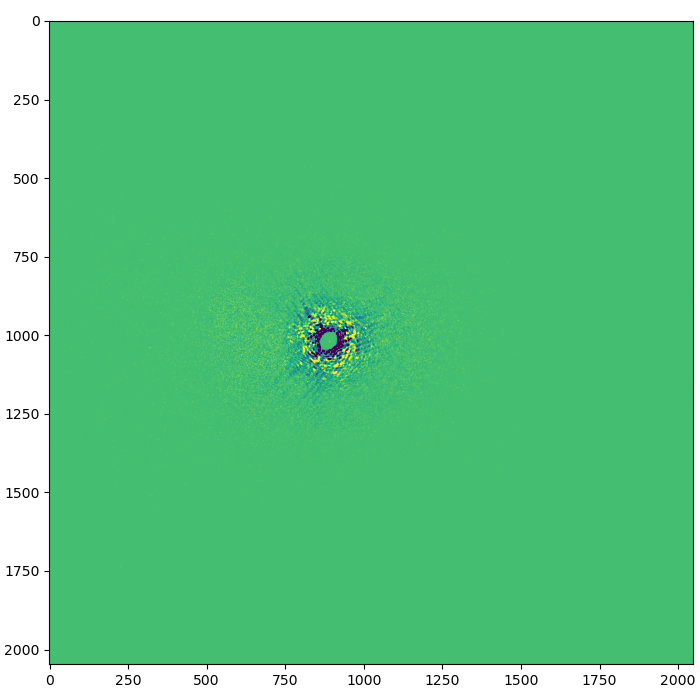

In [ ]:
cimshow(images[0, :10] - topo)

In [115]:
images.shape

(1, 100, 2048, 2048)

interactive(children=(FloatRangeSlider(value=(-0.9899978637695312, 2527.465113769913), description='contrast',…

interactive(children=(IntText(value=1021, description='c0 (vert)', step=0), IntText(value=891, description='c1…

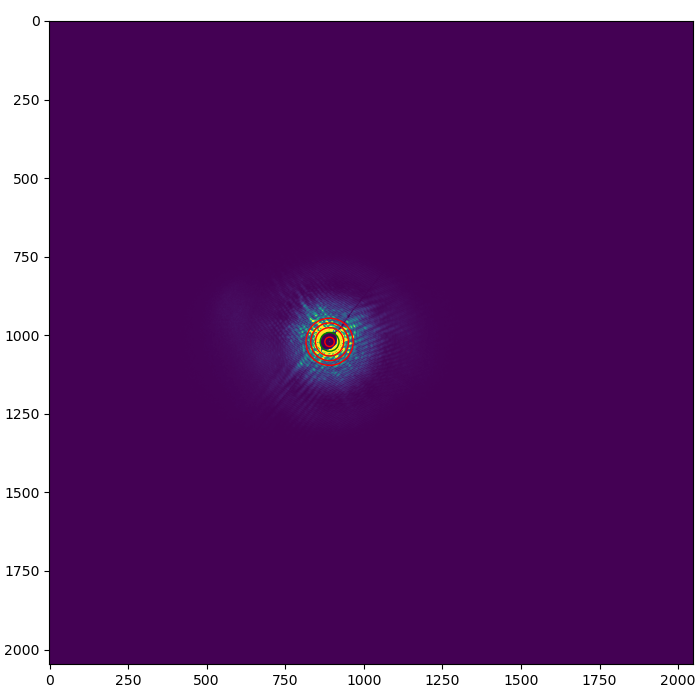

In [ ]:
# Find center position via widget
c0, c1 = [1021, 891]
ic = interactive.InteractiveCenter(image, c0=c0, c1=c1)

In [42]:
# Get center positions
center = [ic.c0, ic.c1]

print(f"Center:", center)

Center: [1021, 891]


## Azimuthal integrator widget for finetuning
More of an "expert widget" which works very well for alignment if you have an Airy Pattern as a scattering image. PyFai transforms images from carthesian detector coordinate system into polar coordinate system with angle `phi` and radial distance `q` as axis (azimuthal transformation). The center of the coordinate system will be defined in the azimuthal integrator class and must not necessarily represents the center coordinates of your image array. If the center is set correctly, all rings of the Airy pattern will be transformed into a straight line in the I(q,chi)-plot as rings appear at a given q for all angles chi.

In [43]:
# Setup azimuthal integrator for virtual geometry
ai = AzimuthalIntegrator(
    dist=experimental_setup["ccd_dist"],
    detector=detector,
    wavelength=experimental_setup["lambda"],
    poni1=center[0]
    * experimental_setup["px_size"]
    * experimental_setup["binning"],  # y (vertical)
    poni2=center[1]
    * experimental_setup["px_size"]
    * experimental_setup["binning"],  # x (horizontal)
)

# Apply to topo and image
shift_c = np.array(image.shape) / 2 - center
im_c = cci.shift_image(image, shift_c)
topo_c = cci.shift_image(topo, shift_c)  # centered image

# Image Registration

Relative drift between data holograms and their corresponding topo holograms is calculated by image registration algorithm. Necessary to get well defined difference hologram. The reference is always the static background image (topo).

## Calculate drift of images

In [44]:
roi_im_reg  = [982 ,1109, 1085 ,1195]
roi_im_reg_s = np.s_[roi_im_reg[0] : roi_im_reg[1], roi_im_reg[2] : roi_im_reg[3]]

shift = cci.image_registration(
    im_c[roi_im_reg_s],
    topo_c[roi_im_reg_s],
    method="dipy",
)
print("Relative shift is: %s" % shift)

Relative shift is: [-0.   -0.02]


## Correct drift of topo

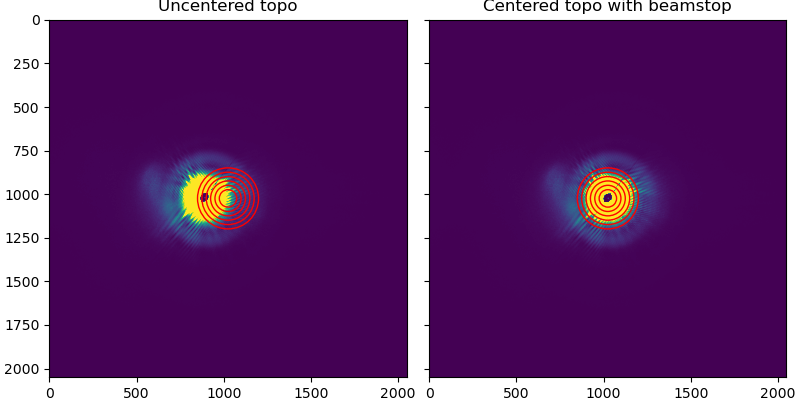

In [45]:
# Correct relative drift
#topo_c = cci.shift_image(topo_c, shift)

# Plot original and shifted holos
mi, ma = np.percentile(np.real(topo_c[topo_c != 0]), (0.1, 99))
fig, ax = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8, 4))
ax[0].imshow(np.real(topo), cmap="viridis", vmin=mi, vmax=ma)
ax[0].set_title("Uncentered topo")
ax[1].imshow(np.real(topo_c), cmap="viridis", vmin=mi, vmax=ma)
ax[1].set_title("Centered topo with beamstop")

# Add circles with different radi r
tmp = np.array(image.shape) / 2
for r in np.arange(50, 200, 25):
    ax[0].add_artist(plt.Circle((tmp[1], tmp[0]), r, fill=None, ec="red"))
    ax[1].add_artist(plt.Circle((tmp[1], tmp[0]), r, fill=None, ec="red"))

# Create beamstops

We want to cover the beamstop with a smooth circle to cover its sharp edges as these would create ringing-like artifacts in the reconstruction plane. Make it only as large as necessary to keep as much information as possible.

In [46]:
def load_poly_coordinates():
    """
    Dictionary that stores polygon corner coordinates of all drawn masks
    Example: How to add masks with name "test":
    mask_coordinates["test"] = copy coordinates from above
    """
    mask_coordinates = dict()
   # mask_coordinates["20260214_medium_BS_center"] = [[(959.7, 1001.3), (981.8, 968.7), (983.7, 960.8), (989.3, 960.5), (1001.3, 954.1), (1021.2, 951.1), (1039.9, 951.1), (1057.1, 955.2), (1060.9, 952.6), (1063.1, 957.5), (1071.0, 958.6), (1078.1, 954.1), (1092.4, 963.5), (1089.8, 971.0), (1096.1, 986.3), (1101.7, 999.5), (1106.2, 1013.7), (1108.5, 1029.8), (1105.1, 1048.6), (1097.6, 1062.4), (1102.9, 1074.1), (1089.8, 1090.5), (1081.5, 1086.8), (1078.9, 1089.4), (1073.3, 1089.4), (1060.1, 1100.3), (1045.5, 1103.7), (1027.9, 1104.4), (1006.5, 1101.8), (993.0, 1096.2), (987.4, 1096.9), (983.3, 1100.7), (966.1, 1089.0), (966.1, 1086.4), (966.8, 1083.8), (968.7, 1076.7), (962.7, 1073.7), (963.8, 1068.1), (958.6, 1059.1), (954.4, 1038.1), (952.6, 1014.1)], [(959.7, 1001.3), (981.8, 968.7), (983.7, 960.8), (989.3, 960.5), (1001.3, 954.1), (1021.2, 951.1), (1039.9, 951.1), (1057.1, 955.2), (1060.9, 952.6), (1063.1, 957.5), (1071.0, 958.6), (1078.1, 954.1), (1092.4, 963.5), (1089.8, 971.0), (1096.1, 986.3), (1101.7, 999.5), (1106.2, 1013.7), (1108.5, 1029.8), (1105.1, 1048.6), (1097.6, 1062.4), (1102.9, 1074.1), (1089.8, 1090.5), (1081.5, 1086.8), (1078.9, 1089.4), (1073.3, 1089.4), (1060.1, 1100.3), (1045.5, 1103.7), (1027.9, 1104.4), (1006.5, 1101.8), (993.0, 1096.2), (987.4, 1096.9), (983.3, 1100.7), (966.1, 1089.0), (966.1, 1086.4), (966.8, 1083.8), (968.7, 1076.7), (962.7, 1073.7), (963.8, 1068.1), (958.6, 1059.1), (954.4, 1038.1), (952.6, 1014.1)], [(959.7, 1001.3), (981.8, 968.7), (983.7, 960.8), (989.3, 960.5), (1001.3, 954.1), (1021.2, 951.1), (1039.9, 951.1), (1057.1, 955.2), (1060.9, 952.6), (1063.1, 957.5), (1071.0, 958.6), (1078.1, 954.1), (1092.4, 963.5), (1089.8, 971.0), (1096.1, 986.3), (1101.7, 999.5), (1106.2, 1013.7), (1108.5, 1029.8), (1105.1, 1048.6), (1097.6, 1062.4), (1102.9, 1074.1), (1089.8, 1090.5), (1081.5, 1086.8), (1078.9, 1089.4), (1073.3, 1089.4), (1060.1, 1100.3), (1045.5, 1103.7), (1027.9, 1104.4), (1006.5, 1101.8), (993.0, 1096.2), (987.4, 1096.9), (983.3, 1100.7), (966.1, 1089.0), (966.1, 1086.4), (966.8, 1083.8), (968.7, 1076.7), (962.7, 1073.7), (963.8, 1068.1), (958.6, 1059.1), (954.4, 1038.1), (952.6, 1014.1)], [(959.7, 1001.3), (981.8, 968.7), (983.7, 960.8), (989.3, 960.5), (1001.3, 954.1), (1021.2, 951.1), (1039.9, 951.1), (1057.1, 955.2), (1060.9, 952.6), (1063.1, 957.5), (1071.0, 958.6), (1078.1, 954.1), (1092.4, 963.5), (1089.8, 971.0), (1096.1, 986.3), (1101.7, 999.5), (1106.2, 1013.7), (1108.5, 1029.8), (1105.1, 1048.6), (1097.6, 1062.4), (1102.9, 1074.1), (1089.8, 1090.5), (1081.5, 1086.8), (1078.9, 1089.4), (1073.3, 1089.4), (1060.1, 1100.3), (1045.5, 1103.7), (1027.9, 1104.4), (1006.5, 1101.8), (993.0, 1096.2), (987.4, 1096.9), (983.3, 1100.7), (966.1, 1089.0), (966.1, 1086.4), (966.8, 1083.8), (968.7, 1076.7), (962.7, 1073.7), (963.8, 1068.1), (958.6, 1059.1), (954.4, 1038.1), (952.6, 1014.1)], [(959.7, 1001.3), (981.8, 968.7), (983.7, 960.8), (989.3, 960.5), (1001.3, 954.1), (1021.2, 951.1), (1039.9, 951.1), (1057.1, 955.2), (1060.9, 952.6), (1063.1, 957.5), (1071.0, 958.6), (1078.1, 954.1), (1092.4, 963.5), (1089.8, 971.0), (1096.1, 986.3), (1101.7, 999.5), (1106.2, 1013.7), (1108.5, 1029.8), (1105.1, 1048.6), (1097.6, 1062.4), (1102.9, 1074.1), (1089.8, 1090.5), (1081.5, 1086.8), (1078.9, 1089.4), (1073.3, 1089.4), (1060.1, 1100.3), (1045.5, 1103.7), (1027.9, 1104.4), (1006.5, 1101.8), (993.0, 1096.2), (987.4, 1096.9), (983.3, 1100.7), (966.1, 1089.0), (966.1, 1086.4), (966.8, 1083.8), (968.7, 1076.7), (962.7, 1073.7), (963.8, 1068.1), (958.6, 1059.1), (954.4, 1038.1), (952.6, 1014.1)], [(959.7, 1001.3), (981.8, 968.7), (983.7, 960.8), (989.3, 960.5), (1001.3, 954.1), (1021.2, 951.1), (1039.9, 951.1), (1057.1, 955.2), (1060.9, 952.6), (1063.1, 957.5), (1071.0, 958.6), (1078.1, 954.1), (1092.4, 963.5), (1089.8, 971.0), (1096.1, 986.3), (1101.7, 999.5), (1106.2, 1013.7), (1108.5, 1029.8), (1105.1, 1048.6), (1097.6, 1062.4), (1102.9, 1074.1), (1089.8, 1090.5), (1081.5, 1086.8), (1078.9, 1089.4), (1073.3, 1089.4), (1060.1, 1100.3), (1045.5, 1103.7), (1027.9, 1104.4), (1006.5, 1101.8), (993.0, 1096.2), (987.4, 1096.9), (983.3, 1100.7), (966.1, 1089.0), (966.1, 1086.4), (966.8, 1083.8), (968.7, 1076.7), (962.7, 1073.7), (963.8, 1068.1), (958.6, 1059.1), (954.4, 1038.1), (952.6, 1014.1)], [(959.7, 1001.3), (981.8, 968.7), (983.7, 960.8), (989.3, 960.5), (1001.3, 954.1), (1021.2, 951.1), (1039.9, 951.1), (1057.1, 955.2), (1060.9, 952.6), (1063.1, 957.5), (1071.0, 958.6), (1078.1, 954.1), (1092.4, 963.5), (1089.8, 971.0), (1096.1, 986.3), (1101.7, 999.5), (1106.2, 1013.7), (1108.5, 1029.8), (1105.1, 1048.6), (1097.6, 1062.4), (1102.9, 1074.1), (1089.8, 1090.5), (1081.5, 1086.8), (1078.9, 1089.4), (1073.3, 1089.4), (1060.1, 1100.3), (1045.5, 1103.7), (1027.9, 1104.4), (1006.5, 1101.8), (993.0, 1096.2), (987.4, 1096.9), (983.3, 1100.7), (966.1, 1089.0), (966.1, 1086.4), (966.8, 1083.8), (968.7, 1076.7), (962.7, 1073.7), (963.8, 1068.1), (958.6, 1059.1), (954.4, 1038.1), (952.6, 1014.1)], [(959.7, 1001.3), (981.8, 968.7), (983.7, 960.8), (989.3, 960.5), (1001.3, 954.1), (1021.2, 951.1), (1039.9, 951.1), (1057.1, 955.2), (1060.9, 952.6), (1063.1, 957.5), (1071.0, 958.6), (1078.1, 954.1), (1092.4, 963.5), (1089.8, 971.0), (1096.1, 986.3), (1101.7, 999.5), (1106.2, 1013.7), (1108.5, 1029.8), (1105.1, 1048.6), (1097.6, 1062.4), (1102.9, 1074.1), (1089.8, 1090.5), (1081.5, 1086.8), (1078.9, 1089.4), (1073.3, 1089.4), (1060.1, 1100.3), (1045.5, 1103.7), (1027.9, 1104.4), (1006.5, 1101.8), (993.0, 1096.2), (987.4, 1096.9), (983.3, 1100.7), (966.1, 1089.0), (966.1, 1086.4), (966.8, 1083.8), (968.7, 1076.7), (962.7, 1073.7), (963.8, 1068.1), (958.6, 1059.1), (954.4, 1038.1), (952.6, 1014.1)], [(959.7, 1001.3), (981.8, 968.7), (983.7, 960.8), (989.3, 960.5), (1001.3, 954.1), (1021.2, 951.1), (1039.9, 951.1), (1057.1, 955.2), (1060.9, 952.6), (1063.1, 957.5), (1071.0, 958.6), (1078.1, 954.1), (1092.4, 963.5), (1089.8, 971.0), (1096.1, 986.3), (1101.7, 999.5), (1106.2, 1013.7), (1108.5, 1029.8), (1105.1, 1048.6), (1097.6, 1062.4), (1102.9, 1074.1), (1089.8, 1090.5), (1081.5, 1086.8), (1078.9, 1089.4), (1073.3, 1089.4), (1060.1, 1100.3), (1045.5, 1103.7), (1027.9, 1104.4), (1006.5, 1101.8), (993.0, 1096.2), (987.4, 1096.9), (983.3, 1100.7), (966.1, 1089.0), (966.1, 1086.4), (966.8, 1083.8), (968.7, 1076.7), (962.7, 1073.7), (963.8, 1068.1), (958.6, 1059.1), (954.4, 1038.1), (952.6, 1014.1)], [(959.7, 1001.3), (981.8, 968.7), (983.7, 960.8), (989.3, 960.5), (1001.3, 954.1), (1021.2, 951.1), (1039.9, 951.1), (1057.1, 955.2), (1060.9, 952.6), (1063.1, 957.5), (1071.0, 958.6), (1078.1, 954.1), (1092.4, 963.5), (1089.8, 971.0), (1096.1, 986.3), (1101.7, 999.5), (1106.2, 1013.7), (1108.5, 1029.8), (1105.1, 1048.6), (1097.6, 1062.4), (1102.9, 1074.1), (1089.8, 1090.5), (1081.5, 1086.8), (1078.9, 1089.4), (1073.3, 1089.4), (1060.1, 1100.3), (1045.5, 1103.7), (1027.9, 1104.4), (1006.5, 1101.8), (993.0, 1096.2), (987.4, 1096.9), (983.3, 1100.7), (966.1, 1089.0), (966.1, 1086.4), (966.8, 1083.8), (968.7, 1076.7), (962.7, 1073.7), (963.8, 1068.1), (958.6, 1059.1), (954.4, 1038.1), (952.6, 1014.1)], [(959.7, 1001.3), (981.8, 968.7), (983.7, 960.8), (989.3, 960.5), (1001.3, 954.1), (1021.2, 951.1), (1039.9, 951.1), (1057.1, 955.2), (1060.9, 952.6), (1063.1, 957.5), (1071.0, 958.6), (1078.1, 954.1), (1092.4, 963.5), (1089.8, 971.0), (1096.1, 986.3), (1101.7, 999.5), (1106.2, 1013.7), (1108.5, 1029.8), (1105.1, 1048.6), (1097.6, 1062.4), (1102.9, 1074.1), (1089.8, 1090.5), (1081.5, 1086.8), (1078.9, 1089.4), (1073.3, 1089.4), (1060.1, 1100.3), (1045.5, 1103.7), (1027.9, 1104.4), (1006.5, 1101.8), (993.0, 1096.2), (987.4, 1096.9), (983.3, 1100.7), (966.1, 1089.0), (966.1, 1086.4), (966.8, 1083.8), (968.7, 1076.7), (962.7, 1073.7), (963.8, 1068.1), (958.6, 1059.1), (954.4, 1038.1), (952.6, 1014.1)], [(959.7, 1001.3), (981.8, 968.7), (983.7, 960.8), (989.3, 960.5), (1001.3, 954.1), (1021.2, 951.1), (1039.9, 951.1), (1057.1, 955.2), (1060.9, 952.6), (1063.1, 957.5), (1071.0, 958.6), (1078.1, 954.1), (1092.4, 963.5), (1089.8, 971.0), (1096.1, 986.3), (1101.7, 999.5), (1106.2, 1013.7), (1108.5, 1029.8), (1105.1, 1048.6), (1097.6, 1062.4), (1102.9, 1074.1), (1089.8, 1090.5), (1081.5, 1086.8), (1078.9, 1089.4), (1073.3, 1089.4), (1060.1, 1100.3), (1045.5, 1103.7), (1027.9, 1104.4), (1006.5, 1101.8), (993.0, 1096.2), (987.4, 1096.9), (983.3, 1100.7), (966.1, 1089.0), (966.1, 1086.4), (966.8, 1083.8), (968.7, 1076.7), (962.7, 1073.7), (963.8, 1068.1), (958.6, 1059.1), (954.4, 1038.1), (952.6, 1014.1)], [(959.7, 1001.3), (981.8, 968.7), (983.7, 960.8), (989.3, 960.5), (1001.3, 954.1), (1021.2, 951.1), (1039.9, 951.1), (1057.1, 955.2), (1060.9, 952.6), (1063.1, 957.5), (1071.0, 958.6), (1078.1, 954.1), (1092.4, 963.5), (1089.8, 971.0), (1096.1, 986.3), (1101.7, 999.5), (1106.2, 1013.7), (1108.5, 1029.8), (1105.1, 1048.6), (1097.6, 1062.4), (1102.9, 1074.1), (1089.8, 1090.5), (1081.5, 1086.8), (1078.9, 1089.4), (1073.3, 1089.4), (1060.1, 1100.3), (1045.5, 1103.7), (1027.9, 1104.4), (1006.5, 1101.8), (993.0, 1096.2), (987.4, 1096.9), (983.3, 1100.7), (966.1, 1089.0), (966.1, 1086.4), (966.8, 1083.8), (968.7, 1076.7), (962.7, 1073.7), (963.8, 1068.1), (958.6, 1059.1), (954.4, 1038.1), (952.6, 1014.1)], [(959.7, 1001.3), (981.8, 968.7), (983.7, 960.8), (989.3, 960.5), (1001.3, 954.1), (1021.2, 951.1), (1039.9, 951.1), (1057.1, 955.2), (1060.9, 952.6), (1063.1, 957.5), (1071.0, 958.6), (1078.1, 954.1), (1092.4, 963.5), (1089.8, 971.0), (1096.1, 986.3), (1101.7, 999.5), (1106.2, 1013.7), (1108.5, 1029.8), (1105.1, 1048.6), (1097.6, 1062.4), (1102.9, 1074.1), (1089.8, 1090.5), (1081.5, 1086.8), (1078.9, 1089.4), (1073.3, 1089.4), (1060.1, 1100.3), (1045.5, 1103.7), (1027.9, 1104.4), (1006.5, 1101.8), (993.0, 1096.2), (987.4, 1096.9), (983.3, 1100.7), (966.1, 1089.0), (966.1, 1086.4), (966.8, 1083.8), (968.7, 1076.7), (962.7, 1073.7), (963.8, 1068.1), (958.6, 1059.1), (954.4, 1038.1), (952.6, 1014.1)], [(959.7, 1001.3), (981.8, 968.7), (983.7, 960.8), (989.3, 960.5), (1001.3, 954.1), (1021.2, 951.1), (1039.9, 951.1), (1057.1, 955.2), (1060.9, 952.6), (1063.1, 957.5), (1071.0, 958.6), (1078.1, 954.1), (1092.4, 963.5), (1089.8, 971.0), (1096.1, 986.3), (1101.7, 999.5), (1106.2, 1013.7), (1108.5, 1029.8), (1105.1, 1048.6), (1097.6, 1062.4), (1102.9, 1074.1), (1089.8, 1090.5), (1081.5, 1086.8), (1078.9, 1089.4), (1073.3, 1089.4), (1060.1, 1100.3), (1045.5, 1103.7), (1027.9, 1104.4), (1006.5, 1101.8), (993.0, 1096.2), (987.4, 1096.9), (983.3, 1100.7), (966.1, 1089.0), (966.1, 1086.4), (966.8, 1083.8), (968.7, 1076.7), (962.7, 1073.7), (963.8, 1068.1), (958.6, 1059.1), (954.4, 1038.1), (952.6, 1014.1)], [(959.7, 1001.3), (981.8, 968.7), (983.7, 960.8), (989.3, 960.5), (1001.3, 954.1), (1021.2, 951.1), (1039.9, 951.1), (1057.1, 955.2), (1060.9, 952.6), (1063.1, 957.5), (1071.0, 958.6), (1078.1, 954.1), (1092.4, 963.5), (1089.8, 971.0), (1096.1, 986.3), (1101.7, 999.5), (1106.2, 1013.7), (1108.5, 1029.8), (1105.1, 1048.6), (1097.6, 1062.4), (1102.9, 1074.1), (1089.8, 1090.5), (1081.5, 1086.8), (1078.9, 1089.4), (1073.3, 1089.4), (1060.1, 1100.3), (1045.5, 1103.7), (1027.9, 1104.4), (1006.5, 1101.8), (993.0, 1096.2), (987.4, 1096.9), (983.3, 1100.7), (966.1, 1089.0), (966.1, 1086.4), (966.8, 1083.8), (968.7, 1076.7), (962.7, 1073.7), (963.8, 1068.1), (958.6, 1059.1), (954.4, 1038.1), (952.6, 1014.1)], [(959.7, 1001.3), (981.8, 968.7), (983.7, 960.8), (989.3, 960.5), (1001.3, 954.1), (1021.2, 951.1), (1039.9, 951.1), (1057.1, 955.2), (1060.9, 952.6), (1063.1, 957.5), (1071.0, 958.6), (1078.1, 954.1), (1092.4, 963.5), (1089.8, 971.0), (1096.1, 986.3), (1101.7, 999.5), (1106.2, 1013.7), (1108.5, 1029.8), (1105.1, 1048.6), (1097.6, 1062.4), (1102.9, 1074.1), (1089.8, 1090.5), (1081.5, 1086.8), (1078.9, 1089.4), (1073.3, 1089.4), (1060.1, 1100.3), (1045.5, 1103.7), (1027.9, 1104.4), (1006.5, 1101.8), (993.0, 1096.2), (987.4, 1096.9), (983.3, 1100.7), (966.1, 1089.0), (966.1, 1086.4), (966.8, 1083.8), (968.7, 1076.7), (962.7, 1073.7), (963.8, 1068.1), (958.6, 1059.1), (954.4, 1038.1), (952.6, 1014.1)], [(959.7, 1001.3), (981.8, 968.7), (983.7, 960.8), (989.3, 960.5), (1001.3, 954.1), (1021.2, 951.1), (1039.9, 951.1), (1057.1, 955.2), (1060.9, 952.6), (1063.1, 957.5), (1071.0, 958.6), (1078.1, 954.1), (1092.4, 963.5), (1089.8, 971.0), (1096.1, 986.3), (1101.7, 999.5), (1106.2, 1013.7), (1108.5, 1029.8), (1105.1, 1048.6), (1097.6, 1062.4), (1102.9, 1074.1), (1089.8, 1090.5), (1081.5, 1086.8), (1078.9, 1089.4), (1073.3, 1089.4), (1060.1, 1100.3), (1045.5, 1103.7), (1027.9, 1104.4), (1006.5, 1101.8), (993.0, 1096.2), (987.4, 1096.9), (983.3, 1100.7), (966.1, 1089.0), (966.1, 1086.4), (966.8, 1083.8), (968.7, 1076.7), (962.7, 1073.7), (963.8, 1068.1), (958.6, 1059.1), (954.4, 1038.1), (952.6, 1014.1)], [(959.7, 1001.3), (981.8, 968.7), (983.7, 960.8), (989.3, 960.5), (1001.3, 954.1), (1021.2, 951.1), (1039.9, 951.1), (1057.1, 955.2), (1060.9, 952.6), (1063.1, 957.5), (1071.0, 958.6), (1078.1, 954.1), (1092.4, 963.5), (1089.8, 971.0), (1096.1, 986.3), (1101.7, 999.5), (1106.2, 1013.7), (1108.5, 1029.8), (1105.1, 1048.6), (1097.6, 1062.4), (1102.9, 1074.1), (1089.8, 1090.5), (1081.5, 1086.8), (1078.9, 1089.4), (1073.3, 1089.4), (1060.1, 1100.3), (1045.5, 1103.7), (1027.9, 1104.4), (1006.5, 1101.8), (993.0, 1096.2), (987.4, 1096.9), (983.3, 1100.7), (966.1, 1089.0), (966.1, 1086.4), (966.8, 1083.8), (968.7, 1076.7), (962.7, 1073.7), (963.8, 1068.1), (958.6, 1059.1), (954.4, 1038.1), (952.6, 1014.1)], [(959.7, 1001.3), (981.8, 968.7), (983.7, 960.8), (989.3, 960.5), (1001.3, 954.1), (1021.2, 951.1), (1039.9, 951.1), (1057.1, 955.2), (1060.9, 952.6), (1063.1, 957.5), (1071.0, 958.6), (1078.1, 954.1), (1092.4, 963.5), (1089.8, 971.0), (1096.1, 986.3), (1101.7, 999.5), (1106.2, 1013.7), (1108.5, 1029.8), (1105.1, 1048.6), (1097.6, 1062.4), (1102.9, 1074.1), (1089.8, 1090.5), (1081.5, 1086.8), (1078.9, 1089.4), (1073.3, 1089.4), (1060.1, 1100.3), (1045.5, 1103.7), (1027.9, 1104.4), (1006.5, 1101.8), (993.0, 1096.2), (987.4, 1096.9), (983.3, 1100.7), (966.1, 1089.0), (966.1, 1086.4), (966.8, 1083.8), (968.7, 1076.7), (962.7, 1073.7), (963.8, 1068.1), (958.6, 1059.1), (954.4, 1038.1), (952.6, 1014.1)], [(959.7, 1001.3), (981.8, 968.7), (983.7, 960.8), (989.3, 960.5), (1001.3, 954.1), (1021.2, 951.1), (1039.9, 951.1), (1057.1, 955.2), (1060.9, 952.6), (1063.1, 957.5), (1071.0, 958.6), (1078.1, 954.1), (1092.4, 963.5), (1089.8, 971.0), (1096.1, 986.3), (1101.7, 999.5), (1106.2, 1013.7), (1108.5, 1029.8), (1105.1, 1048.6), (1097.6, 1062.4), (1102.9, 1074.1), (1089.8, 1090.5), (1081.5, 1086.8), (1078.9, 1089.4), (1073.3, 1089.4), (1060.1, 1100.3), (1045.5, 1103.7), (1027.9, 1104.4), (1006.5, 1101.8), (993.0, 1096.2), (987.4, 1096.9), (983.3, 1100.7), (966.1, 1089.0), (966.1, 1086.4), (966.8, 1083.8), (968.7, 1076.7), (962.7, 1073.7), (963.8, 1068.1), (958.6, 1059.1), (954.4, 1038.1), (952.6, 1014.1)], [(959.7, 1001.3), (981.8, 968.7), (983.7, 960.8), (989.3, 960.5), (1001.3, 954.1), (1021.2, 951.1), (1039.9, 951.1), (1057.1, 955.2), (1060.9, 952.6), (1063.1, 957.5), (1071.0, 958.6), (1078.1, 954.1), (1092.4, 963.5), (1089.8, 971.0), (1096.1, 986.3), (1101.7, 999.5), (1106.2, 1013.7), (1108.5, 1029.8), (1105.1, 1048.6), (1097.6, 1062.4), (1102.9, 1074.1), (1089.8, 1090.5), (1081.5, 1086.8), (1078.9, 1089.4), (1073.3, 1089.4), (1060.1, 1100.3), (1045.5, 1103.7), (1027.9, 1104.4), (1006.5, 1101.8), (993.0, 1096.2), (987.4, 1096.9), (983.3, 1100.7), (966.1, 1089.0), (966.1, 1086.4), (966.8, 1083.8), (968.7, 1076.7), (962.7, 1073.7), (963.8, 1068.1), (958.6, 1059.1), (954.4, 1038.1), (952.6, 1014.1)], [(959.7, 1001.3), (981.8, 968.7), (983.7, 960.8), (989.3, 960.5), (1001.3, 954.1), (1021.2, 951.1), (1039.9, 951.1), (1057.1, 955.2), (1060.9, 952.6), (1063.1, 957.5), (1071.0, 958.6), (1078.1, 954.1), (1092.4, 963.5), (1089.8, 971.0), (1096.1, 986.3), (1101.7, 999.5), (1106.2, 1013.7), (1108.5, 1029.8), (1105.1, 1048.6), (1097.6, 1062.4), (1102.9, 1074.1), (1089.8, 1090.5), (1081.5, 1086.8), (1078.9, 1089.4), (1073.3, 1089.4), (1060.1, 1100.3), (1045.5, 1103.7), (1027.9, 1104.4), (1006.5, 1101.8), (993.0, 1096.2), (987.4, 1096.9), (983.3, 1100.7), (966.1, 1089.0), (966.1, 1086.4), (966.8, 1083.8), (968.7, 1076.7), (962.7, 1073.7), (963.8, 1068.1), (958.6, 1059.1), (954.4, 1038.1), (952.6, 1014.1)], [(959.7, 1001.3), (981.8, 968.7), (983.7, 960.8), (989.3, 960.5), (1001.3, 954.1), (1021.2, 951.1), (1039.9, 951.1), (1057.1, 955.2), (1060.9, 952.6), (1063.1, 957.5), (1071.0, 958.6), (1078.1, 954.1), (1092.4, 963.5), (1089.8, 971.0), (1096.1, 986.3), (1101.7, 999.5), (1106.2, 1013.7), (1108.5, 1029.8), (1105.1, 1048.6), (1097.6, 1062.4), (1102.9, 1074.1), (1089.8, 1090.5), (1081.5, 1086.8), (1078.9, 1089.4), (1073.3, 1089.4), (1060.1, 1100.3), (1045.5, 1103.7), (1027.9, 1104.4), (1006.5, 1101.8), (993.0, 1096.2), (987.4, 1096.9), (983.3, 1100.7), (966.1, 1089.0), (966.1, 1086.4), (966.8, 1083.8), (968.7, 1076.7), (962.7, 1073.7), (963.8, 1068.1), (958.6, 1059.1), (954.4, 1038.1), (952.6, 1014.1)]]
   # mask_coordinates["20260214_medium_BS_UR_wire"] = [[(1097.9, 958.9), (1109.5, 959.6), (1110.5, 945.0), (1151.6, 893.4), (1341.2, 644.4), (1620.2, 258.5), (1771.7, 11.0), (1742.9, 13.7), (1659.2, 156.3), (1584.6, 267.5), (1431.5, 490.0), (1276.7, 701.2), (1155.0, 856.6), (1097.7, 930.7), (1069.7, 960.4), (1087.8, 974.7)]]
   # mask_coordinates["20260214_medium_BS_LL_wire"] = [[(988.8, 1093.7), (985.5, 1098.6), (977.4, 1101.6), (973.8, 1109.5), (932.3, 1160.9), (893.5, 1212.2), (831.7, 1289.8), (612.8, 1585.0), (477.1, 1788.1), (345.8, 1982.4), (316.9, 2033.2), (282.8, 2035.8), (323.1, 1973.7), (447.4, 1787.2), (588.3, 1577.1), (720.6, 1397.6), (774.5, 1325.9), (876.1, 1196.4), (896.8, 1169.6), (927.0, 1135.1), (955.0, 1103.8), (956.1, 1097.8), (963.2, 1095.3), (972.4, 1079.4)]]
   # mask_coordinates["20260214_medium_BS_LR_wire"] = [[(1077.7, 1084.9), (1094.5, 1059.7), (1095.3, 1066.5), (1101.7, 1077.7), (1108.5, 1081.3), (1112.5, 1090.1), (1130.5, 1095.7), (1143.7, 1114.1), (1158.5, 1123.7), (1220.1, 1169.7), (1261.3, 1200.9), (1323.9, 1250.0), (1486.4, 1368.4), (1632.2, 1475.6), (1883.7, 1648.0), (2041.6, 1753.0), (2041.7, 1786.0), (1928.3, 1707.2), (1684.7, 1540.3), (1590.6, 1473.5), (1430.5, 1359.5), (1288.5, 1251.3), (1169.3, 1156.9), (1134.1, 1126.9), (1120.1, 1110.5), (1105.7, 1101.7), (1098.1, 1092.5), (1085.7, 1086.1)]]
   # mask_coordinates["20260214_medium_BS_UL_wire"] = [[(964.5, 995.7), (986.6, 964.0), (974.2, 968.1), (965.6, 963.1), (954.3, 955.6), (944.1, 949.5), (933.6, 939.0), (918.9, 927.7), (898.6, 913.0), (882.4, 901.7), (861.7, 885.9), (842.1, 872.0), (827.0, 860.7), (807.5, 847.1), (782.2, 829.1), (753.3, 809.5), (690.0, 764.0), (550.7, 670.2), (320.4, 497.7), (219.7, 420.5), (167.2, 375.0), (136.9, 358.4), (141.0, 399.8), (204.5, 439.8), (273.5, 496.4), (328.6, 530.9), (422.4, 602.6), (549.3, 690.9), (668.0, 773.6), (732.8, 823.3), (763.4, 842.6), (796.2, 866.0), (833.5, 889.5), (873.5, 918.5), (897.4, 934.5), (919.0, 948.8), (930.0, 954.3), (935.5, 959.3), (948.0, 968.1), (956.2, 977.8), (960.7, 984.9)]]

    mask_coordinates["20260214_dot_BS_triangle_upper_left"] = [[(1007.0, 1048.1), (827.6, 1269.4), (826.7, 1259.9), (925.7, 1135.8), (1000.9, 1045.9)], [(837.3, 1268.5), (837.3, 1268.5), (570.5, 1573.2), (566.8, 1560.8), (826.3, 1253.9)], [(567.3, 1583.9), (352.9, 1856.1), (345.6, 1849.3), (567.3, 1559.7), (577.5, 1570.3)], [(1048.6, 999.0), (1057.1, 986.6), (1068.9, 980.7), (1078.7, 961.7), (1096.3, 938.2), (1319.3, 665.5), (1319.3, 665.5), (1304.3, 661.6), (1042.7, 988.5)], [(1313.5, 673.2), (1542.8, 349.5), (1525.0, 349.5), (1303.3, 665.1)], [(393.3, 1.3), (134.5, 247.4), (1.0, 105.8), (1.0, 1.9)]]
    mask_coordinates["20260214_dot_BS_right_wire2"] = [[(1007.0, 1048.1), (827.6, 1269.4), (826.7, 1259.9), (925.7, 1135.8), (1000.9, 1045.9)], [(837.3, 1268.5), (837.3, 1268.5), (570.5, 1573.2), (566.8, 1560.8), (826.3, 1253.9)], [(567.3, 1583.9), (352.9, 1856.1), (345.6, 1849.3), (567.3, 1559.7), (577.5, 1570.3)], [(1048.6, 999.0), (1057.1, 986.6), (1068.9, 980.7), (1078.7, 961.7), (1096.3, 938.2), (1319.3, 665.5), (1319.3, 665.5), (1304.3, 661.6), (1042.7, 988.5)], [(1313.5, 673.2), (1542.8, 349.5), (1525.0, 349.5), (1303.3, 665.1)]]
    mask_coordinates["20260214_dot_BS_right_wire1"] = [[(1007.0, 1048.1), (827.6, 1269.4), (826.7, 1259.9), (925.7, 1135.8), (1000.9, 1045.9)], [(837.3, 1268.5), (837.3, 1268.5), (570.5, 1573.2), (566.8, 1560.8), (826.3, 1253.9)], [(567.3, 1583.9), (352.9, 1856.1), (345.6, 1849.3), (567.3, 1559.7), (577.5, 1570.3)], [(1048.6, 999.0), (1057.1, 986.6), (1068.9, 980.7), (1078.7, 961.7), (1096.3, 938.2), (1319.3, 665.5), (1319.3, 665.5), (1304.3, 661.6), (1042.7, 988.5)]]
    mask_coordinates["20260214_dot_BS_left_wire3"] =[[(1007.0, 1048.1), (827.6, 1269.4), (826.7, 1259.9), (925.7, 1135.8), (1000.9, 1045.9)], [(837.3, 1268.5), (837.3, 1268.5), (570.5, 1573.2), (566.8, 1560.8), (826.3, 1253.9)], [(567.3, 1583.9), (352.9, 1856.1), (345.6, 1849.3), (567.3, 1559.7), (577.5, 1570.3)]]
    mask_coordinates["20260214_dot_BS_left_wire2"] = [[(1007.0, 1048.1), (827.6, 1269.4), (826.7, 1259.9), (925.7, 1135.8), (1000.9, 1045.9)], [(837.3, 1268.5), (837.3, 1268.5), (570.5, 1573.2), (566.8, 1560.8), (826.3, 1253.9)]]
    mask_coordinates["20260214_dot_BS_left_wire1"] = [[(1007.0, 1048.1), (827.6, 1269.4), (826.7, 1259.9), (925.7, 1135.8), (1000.9, 1045.9)]]
    mask_coordinates["20260214_dead_pixels"] = [[(1108.2, 1123.6), (1103.7, 1129.3), (1103.3, 1136.4), (1107.7, 1138.6), (1114.0, 1143.2), (1114.0, 1143.2), (1120.2, 1139.5), (1126.0, 1135.0), (1126.3, 1129.3), (1126.3, 1129.3), (1126.3, 1128.8), (1123.2, 1124.9), (1119.2, 1123.1), (1114.9, 1120.5)]]
    mask_coordinates["20260214_dot_BS_center"] = [[(1042.1, 990.4), (1030.8, 988.4), (1020.1, 988.1), (1006.7, 995.0), (998.5, 1005.8), (995.2, 1019.1), (995.2, 1030.7), (996.2, 1037.6), (998.3, 1043.5), (996.5, 1050.2), (970.3, 1085.0), (973.4, 1089.4), (1004.9, 1050.7), (1011.3, 1049.9), (1029.3, 1048.1), (1040.6, 1040.9), (1050.8, 1028.9), (1054.9, 1019.4), (1054.4, 1010.9), (1052.1, 1001.9), (1050.3, 996.0), (1059.3, 985.0), (1068.3, 980.1), (1074.4, 969.1), (1065.7, 965.5), (1051.1, 983.0), (1043.1, 987.1)]]
    mask_coordinates["20260214_dot_BS_outter_wires"] = [[(1286.3, 704.7), (1545.1, 357.1), (1622.8, 250.2), (1767.8, 26.9), (1784.7, 1.0), (1768.9, -0.1), (1689.1, 128.7), (1553.0, 317.7), (1449.5, 465.1), (1278.5, 694.6)], [(770.7, 1325.7), (771.7, 1336.1), (537.4, 1619.3), (419.8, 1764.0), (293.8, 1939.0), (224.0, 2045.7), (203.2, 2045.7), (295.9, 1911.4), (452.1, 1706.2), (639.5, 1478.2)]]
    mask_coordinates["20260214_dot_BS_LHS"] = [[(146.6, 8.7), (149.3, 2044.7), (1.2, 2044.7), (1.2, 1.8)]]
    mask_coordinates["20260214_dot_BS_RHS"] = [[(1832.3, 1540.0), (1851.2, 1517.2), (2043.2, 1658.6), (2044.2, 1697.8), (1833.8, 1542.0)]]
    return mask_coordinates

Text(0.5, 1.0, '1 - mask_draw')

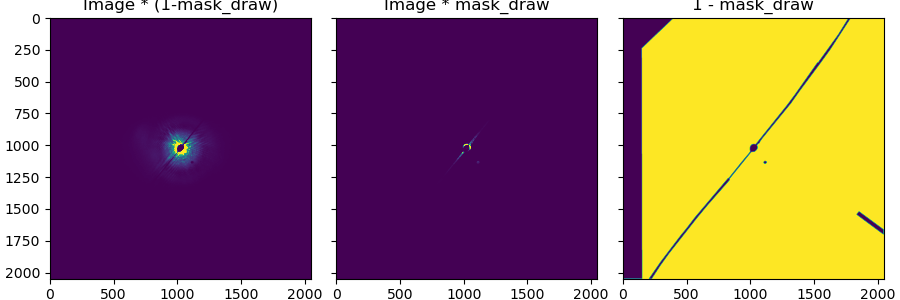

In [47]:
# Which drawn masks do you want to load? You can combine multiple masks from
# load_poly_coordinates(). Just add names of mask as strings to list like
# ["bs_small","bs_medium"]
polygon_names = ["20260214_dot_BS_triangle_upper_left","20260214_dot_BS_right_wire2","20260214_dot_BS_right_wire1","20260214_dot_BS_left_wire3","20260214_dot_BS_left_wire2", "20260214_dot_BS_left_wire1", "20260214_dead_pixels", "20260214_dot_BS_center", "20260214_dot_BS_outter_wires", "20260214_dot_BS_LHS", "20260214_dot_BS_RHS"]# ["epoxy_bs"] ["bs_test"]
mask_draw = mask_lib.load_poly_masks(
    image.shape,
    load_poly_coordinates(),
    polygon_names,
)

# Plot image with beamstop and valid pixel mask
fig, ax = plt.subplots(1, 3, sharex=True, sharey=True, figsize=(9, 3))
mi, ma = np.percentile(im_c * (1 - mask_draw), [0.1, 99.9])
ax[0].imshow(im_c * (1 - mask_draw), cmap="viridis", vmin=mi, vmax=ma)
ax[0].set_title("Image * (1-mask_draw)")

# mi, ma = np.percentile(im_c * mask_draw, [0.1, 90])
ax[1].imshow(im_c * mask_draw, vmin=mi, vmax=ma)
ax[1].set_title("Image * mask_draw")

ax[2].imshow(1 - mask_draw)
ax[2].set_title("1 - mask_draw")

## Finetuning of mask position

interactive(children=(FloatRangeSlider(value=(-0.979995846748352, 2527.4647734378814), description='contrast',…

interactive(children=(FloatSlider(value=2.5, description='shift_ver', layout=Layout(width='350px'), max=1024.0…

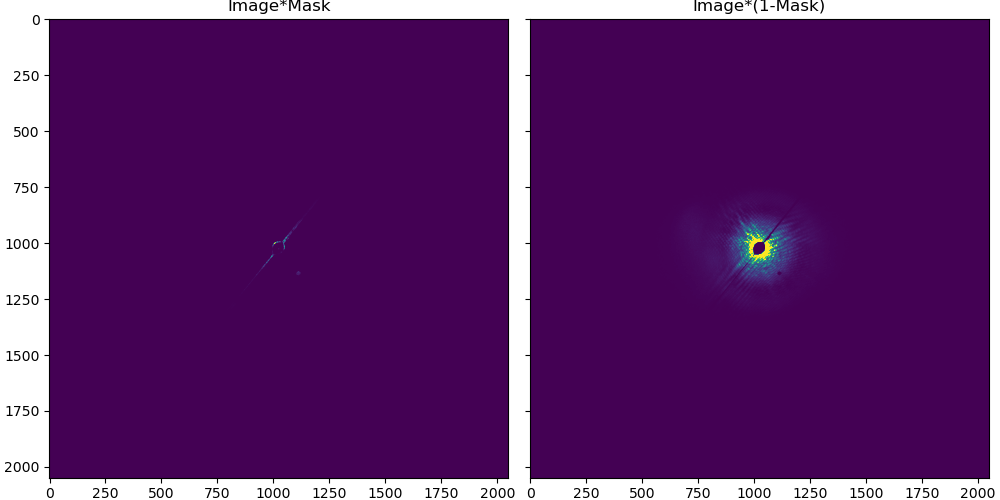

In [48]:
# Use widget to shift and expand or shrink the mask
ss_mask = interactive.Shift_Scale_Mask(im_c, mask_draw, [2.5,-2], scale=-2)

In [49]:
# Take mask, shift and scaling from widget
mask_draw, mask_shift, mask_scale = ss_mask.get_mask()

## Overview beamstops
Verify good beamstop alignment

Text(0.5, 1.0, 'Image-Topo')

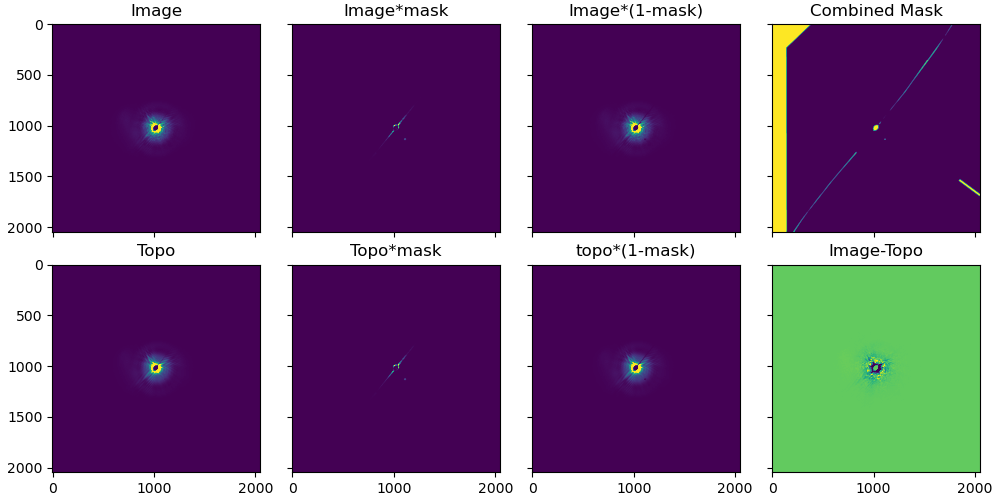

In [50]:
# Smoothing of beamstop mask
bs_smoothing = 2

# Add circular beamstop mask
mask_im = mask_draw.copy()
mask_topo = mask_draw.copy()

# Mask over-saturated pixel
mask_im = mask_im + (im_c > experimental_setup["oversaturation"])
mask_topo = mask_topo + (topo_c > experimental_setup["oversaturation"])

# Combine both
mask_pixel = mask_im + mask_topo
mask_pixel[mask_pixel > 1] = 1
mask_pixel=scipy.ndimage.binary_dilation(mask_pixel, iterations=2)

# Create smooth mask for FTH reconstructions
footprint = skimage.morphology.disk(3 * bs_smoothing)
mask_pixel_smooth = skimage.morphology.dilation(mask_pixel, footprint)
mask_pixel_smooth = gaussian_filter(mask_pixel_smooth, bs_smoothing)

# Plot both
fig, ax = plt.subplots(2, 4, figsize=(10, 5), sharex=True, sharey=True)
mi, ma = np.percentile(im_c, [1, 99.9])
ax[0, 0].imshow(im_c, vmin=mi, vmax=ma)
ax[0, 0].set_title("Image")
mi, ma = np.percentile(im_c * mask_im, [1, 99.99])
ax[0, 1].imshow(im_c * mask_im, vmin=mi, vmax=ma)
ax[0, 1].set_title("Image*mask")
mi, ma = np.percentile(im_c * (1 - mask_im), [0.1, 99.9])
ax[0, 2].imshow(im_c * (1 - mask_im), vmin=mi, vmax=ma)
ax[0, 2].set_title("Image*(1-mask)")
ax[0, 3].imshow(mask_pixel_smooth)
ax[0, 3].set_title("Combined Mask")

mi, ma = np.percentile(topo_c, [1, 99.9])
ax[1, 0].imshow(topo_c, vmin=mi, vmax=ma)
ax[1, 0].set_title("Topo")
mi, ma = np.percentile(topo_c * mask_im, [1, 99.99])
ax[1, 1].imshow(topo_c * mask_topo, vmin=mi, vmax=ma)
ax[1, 1].set_title("Topo*mask")
mi, ma = np.percentile(topo_c * (1 - mask_topo), [0.1, 99.9])
ax[1, 2].imshow(topo_c * (1 - mask_topo), vmin=mi, vmax=ma)
ax[1, 2].set_title("topo*(1-mask)")
mi, ma = np.percentile((im_c - topo_c) * (1 - mask_pixel_smooth), [0.1, 99.9])
ax[1, 3].imshow((im_c - topo_c) * (1 - mask_pixel_smooth), vmin=mi, vmax=ma)
ax[1, 3].set_title("Image-Topo")

# Here: Calculate difference holograms

You can see the reconstrution of the magnetization only after subtracting the large background that you get from the diffraction on the circular object aperture (Airy Pattern). This might require a scaling factor to correct intensity changes between the hologram and the topo. Scaling factor will be determined automatically by a linear fit. If the fit seems off, there might be an issue with the data

In [51]:
# Get scaling factor and offset
factor, offset = cci.dyn_factor(
    im_c * (1 - mask_pixel),
    topo_c * (1 - mask_pixel),
    method="correlation",
    verbose=True,
    plot=False,
)
#factor = 1
#offset = 0
# Calculate differences (magnetic) and sums (topographc) contrast holograms.
# _c: centered, without beamstop, _b: centered, with beamstop
diff_c = im_c / factor - topo_c - offset
sum_c = im_c / factor + topo_c - offset

Linear Fit: 0.7775*x + 2.1921


# Reconstruct Diff Holos (FTH)

Reconstruct the hologram.

0. If you are doing heraldo, determine the rotation angle of the hologram
1. Choose a region of interest (ROI) which means selecting one reconstruction from the reconstruction plane.
2. Propagate the image and shift the phase for maximal contrast and sharpness in your ROI

## Set Patterson Map ROI

Choose the reconstructions as the ROI.

1. Zoom into the image and adjust your FOV until you are satisfied.
2. Save the axes coordinates.

In [52]:
# CROPPING IMAGE

crop=700
if im_c.shape[0]==2048:
    roicrop=np.s_[crop:-crop,crop:-crop]
    #holo=holo[roicrop]
    im_c=im_c[roicrop]
    topo_c=topo_c[roicrop]
    mask_pixel_smooth=mask_pixel_smooth[roicrop]
    mask_pixel=mask_pixel[roicrop]

    diff_c=diff_c[roicrop]
    sum_c=sum_c[roicrop]
    

In [53]:
im_c.shape

(648, 648)

interactive(children=(FloatRangeSlider(value=(0.0007131651392043677, 1.9465728300240008), description='contras…

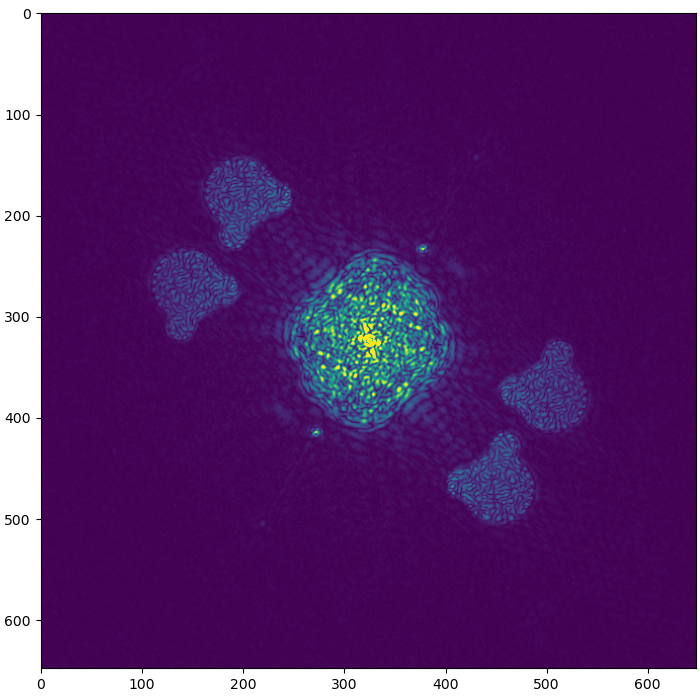

In [54]:
# Choose contrast mode
# diff_c: magnetic contrast only
# sum_c: topographic contrast only
holo = diff_c * (1 - mask_pixel_smooth)
#holo = sum_c * (1 - mask_pixel_smooth)
#holo=im_c.copy()
tmp = fth.reconstruct(holo)

fig, ax = cimshow(np.abs(tmp), cmap="viridis")

In [55]:
# Execute to get roi
x1, x2 = ax.get_xlim()
y2, y1 = ax.get_ylim()
roi = np.array([y1, y2, x1, x2]).astype(int)  # ystart, ystop, xstart, xstop
roi = [350, 604, 390 ,638]
roi=[136 ,237, 148, 256]
roi_s = np.s_[roi[0] : roi[1], roi[2] : roi[3]]
print(f"Roi Reco:{roi}")

Roi Reco:[136, 237, 148, 256]


## Tune propagation and phase
Focus the image by tuning the propagation distance. This really works like focussing in a microscope.
Phase slider will move contrast between real and imaginary part. Usually we use the phase which maximizes the contrast in the real part.

interactive(children=(FloatSlider(value=0.15, description='propagation[um]', layout=Layout(width='90%'), max=1…

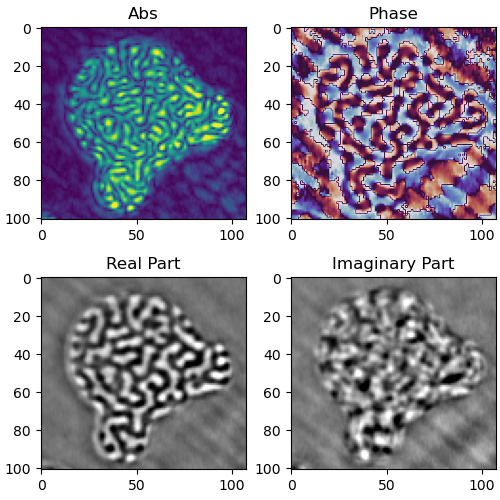

In [56]:
# Widget
holo = sum_c * (1 - mask_pixel_smooth)
holo = diff_c.copy() * (1 - mask_pixel_smooth)

#holo=im_c.copy()
slider_prop, slider_phase, slider_dx, slider_dx=reco.focus(
    holo,
    holo,
    roi_s,
    phase=-2.38, #2.4,  # Initial value
    prop_dist=0.15, #1.26,  # Initial value
    experimental_setup=experimental_setup,
    scale=(.1, 99.9),
    operation="+",
)

In [57]:
# Read prop dist and phase from widget
prop_dist = slider_prop.value
phase = slider_phase.value

print(f"Propagation distance: %0.2f" % prop_dist)
print(f"Phase: %0.2f" % phase)

Propagation distance: 0.15
Phase: -2.38


## Save reconstruction

Save png files of the images and a h5 file containing all important variables

In [58]:
# Style of reconstruction plot
def plot_recon(recon, title, rvmin = 1, rvmax = 99):
    # Plot
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    fig.suptitle(title)

    vmin, vmax = np.percentile(np.real(recon), (rvmin, rvmax))
    t_im1 = ax[0].imshow(np.real(recon), vmin=vmin, vmax=vmax, cmap="gray")
    ax[0].set_title("Real")
    plt.colorbar(t_im1, ax=ax[0], aspect=50)

    vmin, vmax = np.percentile(np.imag(recon), (1, 99))
    t_im2 = ax[1].imshow(np.imag(recon), vmin=vmin, vmax=vmax, cmap="gray")
    ax[1].set_title("Imag")
    plt.colorbar(t_im2, ax=ax[1], aspect=50)

In [59]:
def get_title(data_key, im_id, topo_id, CDI=False, Framenumber= None): #needs to be updated
    # Rotation in title
    if data_key is not None:
        data = load_key(im_id,mnemonics[data_key])

    if CDI is False:
        mode = "FTH"
    elif CDI is True:
        mode = "CDI"

    if data_key == "magnet_mT":
        if Framenumber != None:
            title = "Image %s - %s %s: @ %.2f mA " % (
                im_id,
                topo_id,
                mode,
                data[Framenumber]*1000,
            )
        else:
            print(data)
            title = "Image %s - %s %s: @ %.2f mA " % (
                im_id,
                topo_id,
                mode,
                data*1000,
            )

    elif data_key == "energy":
        title = "Image %s - %s %s: %s = %.2f " % (
            im_id,
            topo_id,
            mode,
            data_key,
            data,
        )
    elif data_key == "magnet_A":
        if Framenumber is not None:
            title = "Image %s - %s %s @ %.2f A, %.2f K " % (
                im_id,
                topo_id,
                mode,
                load_key(im_id,mnemonics["magnet_A"])[Framenumber],
                load_key(im_id,mnemonics["cryo"])[Framenumber],
        )
        else: 
            title = "Image %s - %s %s @ %.2f A, %.2f K " % (
                im_id,
                topo_id,
                mode,
                load_key(im_id,mnemonics["magnet_A"]),
                load_key(im_id,mnemonics["cryo"]),
        )
    else:
        title = "Image %s - %s %s " % (
            im_id,
            topo_id,
            mode,
        )
    if Framenumber != None:
        title += f"Frame: {Framenumber}"

    return title


Saving: /asap3/petra3/gpfs/p04/2026/data/11022228/processed/Recon_ImId_2925_RefId_2923_battistr.png
Now Saving: /asap3/petra3/gpfs/p04/2026/data/11022228/processed/Logs/Data_ImId_2925_RefId_2923_battistr


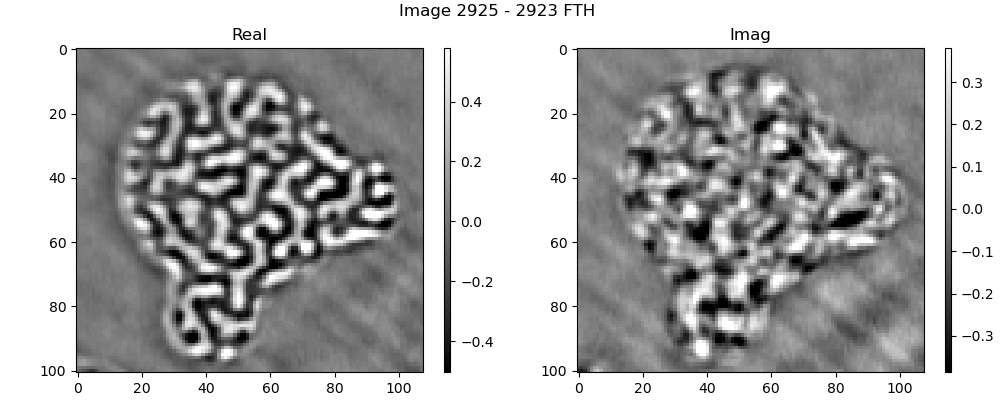

In [60]:
# Create plot
holo = diff_c * (1 - mask_pixel_smooth)

# Reconstruct
recon = fth.reconstruct(
        fth.propagate(holo, prop_dist * 1e-6, experimental_setup=experimental_setup)
        * np.exp(1j * phase)
    )

# Create plot
title = get_title(None, im_id, topo_id)
plot_recon(recon[roi_s], title)

# Save images
fname = join(
    folder_general,
    "Recon_ImId_%s_RefId_%s_%s.png" % (im_id, topo_id, USER),
)
print("Saving: %s" % fname)
plt.savefig(fname, bbox_inches="tight", transparent=False)

# Save hdf5 file
save_fth_h5()

In [61]:
# Closes all existing plots
plt.close("all")

# Batch processing FTH (update!)

In [105]:
# Define the sets for reconstructions. You can make a list or use np.arange
# im_id_set should always have ids of positive helicity holograms,
# topo_id_set those of negative helicity or a hologram of a saturated state

# You can also use nested lists: 
# in case topo_id_set = [[id1,id2],id3 it will use the sum hologram 
# calculated from [id1,id2] as topo


im_ids = 2924 
topo_id = 2923
dark_id = 2926

# In case of single helicity reconstructions, adapt the helicity
# for contrast inversion
helicity = 1 #* np.ones(len(im_ids), dtype=int)  # [1,-1]


# load topo and dark

In [106]:

# LOAD DARK AND TOPO


dark, _ = load_processing(dark_id)
print(dark.shape)


# Construct topo holo from two helicity images
if isinstance(topo_id, list):
    print("Using Topo from sum of two helicity holograms")
    pos_id = topo_id[0]
    neg_id = topo_id[1]

    try:
        topo = load_topo_holo(pos_id, neg_id) / 2
    except:
        topo = load_topo_holo(neg_id, pos_id) / 2
    topo = cci.shift_image(
        topo, -shift_c
    )  # shift out of center so you don't need to change the worker

# usual case, single topo holo
else:
    # Load data
    print(f"Loading imageId: %04d, topoId: %04d" % (im_id, topo_id))
    topo, _ = load_processing(topo_id)

    if dark_id is not None:
        topo = topo - dark


['/asap3/petra3/gpfs/p04/2026/data/11022228/raw/2602_orbitronics_02926/marana/2602_orbitronics_02926_000000.nx']


  0%|          | 0/1 [00:00<?, ?it/s]

(2048, 2048)
Loading imageId: 2924, topoId: 2923
['/asap3/petra3/gpfs/p04/2026/data/11022228/raw/2602_orbitronics_02923/marana/2602_orbitronics_02923_000000.nx']


  0%|          | 0/1 [00:00<?, ?it/s]

# load scan_axis (magnet data)

In [108]:
images.shape

AttributeError: 'list' object has no attribute 'shape'

In [ ]:
# Which data from nexus files to load? (e.g. "energy","master_energy","srotz","magnet_A", "cryo" ...)
key = "magnet_A"
# Use individual image stacks of each scan (e.g., from ascan) id or average of each id?
use_sub_frame = True

# Sorting of data?
sort = False

## Normalize?
normalization = False
norm_key = "maxibeckhoff1adc2_rmean"

# SINGLE PHOTON COUNTING PARAMS
sigma=(0,0.5,0.5)
thr=-3

images,darks, scan_axis, scan_axis2, norm = [], [], [],[], []
print("Loading one dark for all scans")


# Load data

for i, im_id in enumerate(tqdm(im_ids,desc="Im_ids")):
    
    # Load scan axis or single image data

    scan_axis.append(load_key(im_id,mnemonics[key]))

print("Data loaded!")

Loading one dark for all scans


Im_ids:   0%|          | 0/1 [00:00<?, ?it/s]

Data loaded!


In [65]:
# Get one lambda value
if key == "master_energy":
    energy_lambda = cci.photon_energy_wavelength(scan_axis[0])
else: 
    energy_lambda = cci.photon_energy_wavelength(load_key(im_id, mnemonics["energy"]))

# Ugly handling of use subframes
try:
    scan_axis = np.stack(scan_axis)
except:
    scan_axis = np.concatenate(scan_axis)

scan_axis = np.squeeze(scan_axis)

In [66]:
# less ugly Automatic processing of image stacks
recons_name = []  # for gifs

for ii,magnet_A in enumerate(scan_axis):
    if ii>0:
        print(ii,magnet_A)
    
        image=load_images(im_id, file_indices = [ii])
        image=np.squeeze(image)
        image=np.average(image, axis=0)
        
        image-=dark
    
        worker_dict = worker(image, topo, crop=200)

        holo=worker_dict["diff_c"]
        
        if False:
            prop_dists=np.arange(-2,2,0.05)
            temp2=np.zeros((prop_dists.size))
            for ii,pr in enumerate(prop_dists):
                #fig,ax=plt.subplots()
                temp=np.real(fth.reconstruct(fth.propagate(holo, pr*1e-6, experimental_setup))* np.exp(1j*phase))
                temp=temp[roi_s]
                temp=scipy.ndimage.sobel(temp, axis=0)**2+scipy.ndimage.sobel(temp, axis=1)**2
                temp2[ii]=np.sum(temp)
            x0=np.argmax(temp2)
            prop_dist=prop_dists[x0] 
            print(prop_dist)
            
            worker_dict = worker(image, topo, crop=200)
            

        # Load energy and add to experimental setup
        experimental_setup["energy"] = load_key(im_id, "/scan/instrument/collection/mono")
        experimental_setup["lambda"] = helper.photon_energy_wavelength(
            experimental_setup["energy"], input_unit="eV"
        )
    
        # Reconstruct
        recon = worker_dict["recon"]
        
        # Plot
        title = "%d - %0.2fA"%(im_id,magnet_A)
        #get_title("magOOP", im_id, topo_id, CDI=False)
        plot_recon(recon[roi_s], title)
    
        # Save images
        fname = join(
            folder_general,
            "Recon_ImId_%04d_RefId_%s_fth_diff_stack_%s=%0.2fA_%s.png" % (im_id, topo_id,key,magnet_A, USER),
        )
        print("Saving: %s" % fname)
        plt.savefig(fname, bbox_inches="tight", transparent=False)
    
        # Optional: Save hdf5 file of fth data
        save_fth_h5()
        recons_name.append(fname)
    
        print(" ")
print("FTH stack processing finished")
helper.create_gif(recons_name,join(folder_general,f"Scan_{im_id}_{USER}.gif"),fps = 3,loop = 0)

1 0.98356205225
['/asap3/petra3/gpfs/p04/2026/data/11022228/raw/2602_orbitronics_02924/marana/2602_orbitronics_02924_000001.nx']


  0%|          | 0/1 [00:00<?, ?it/s]

Relative shift is: [-0.02 -0.  ]


ValueError: operands could not be broadcast together with shapes (1648,1648) (648,648) 

In [57]:
plt.close("all")

interactive(children=(FloatSlider(value=-2.38, description='propagation[um]', layout=Layout(width='90%'), max=…

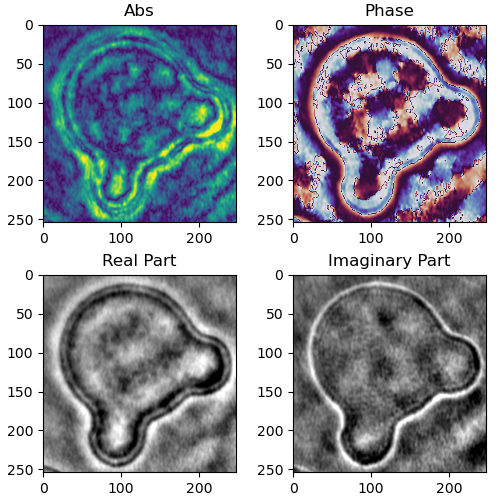

In [58]:
# Widget
holo=worker_dict["diff_c"]

phase=0.52
#holo=im_c.copy()
slider_prop, slider_phase, slider_dx, slider_dx=reco.focus(
    holo,
    holo,
    roi_s,
    phase=phase,  # Initial value
    prop_dist=prop_dist,  # Initial value
    experimental_setup=experimental_setup,
    scale=(.1, 99.9),
    operation="+",
)

# CDI Reconstruction

## Create set of pos and neg helicity holograms

CDI algorithm needs holograms recorded wih both helicity ($\sigma = \pm 1$) as input. We use will calculate those from our previously centered and intensity normalized holograms according to;´; 

$Image(\sigma) = Topo + \sigma \cdot diff $,

In [68]:
# Choose either option
pos = (sum_c + diff_c) / 2
neg = (sum_c - diff_c) / 2

pos = im_c/factor
neg = topo_c.copy()

crop=0
if pos.shape[0]==2048 and crop>0:
    pos=pos[crop:-crop,crop:-crop]
    neg=neg[crop:-crop,crop:-crop]

print(pos.shape)

(648, 648)


## Create Support mask
The support mask is the real-space constraint used for the (holographically-aided) phase retrieval, i.e., certain details about our sample like the sample geometry. For our samples we can directly derive a very strong constraint: The FTH reconstructions show us previsely the actual real-space sample structure, i.e., the arrangement of our aperture where x-rays are transmitted ("1") while the masked areas show no transmission ("0"). We will therefore create a binary mask that reflects this transmission as an input for the phase retrieval.

How to draw a support mask: Create a binary mask of the locations of sample apertures in the fth reconstruction. Areas with apertures are "1". Select only a single set of reconstructions (object & reference apertures) that originate from a single reference. Use the widget!

### Option 1: Execute if you want to create a new support mask
If you really want to create a new support mask, execute next cell and then the "InteractiveCircleCoordinates"-widget

In [77]:
supportmask=1.*(plt.imread("supportmask_00_2.png")[:,:,0]==1)
from skimage.draw import disk
yy,xx=disk(np.array(supportmask.shape)//2,4)
supportmask[yy,xx]=1
supportmask.shape, pos.shape

((648, 648), (648, 648))

Cover the object & reference apertures for each set of reconstructions that originates from the same reference with circles.
Optimization: Change one circle parameter, calc phase retrieval image, compare with images reconstructed with old circle parameter. Repeat!
Use circle index slider to change between circles. The active circle is highlighted in red.
Right click to move circle to mouse position!


interactive(children=(FloatRangeSlider(value=(-5.17259041266563, 5.853561576932808), description='contrast', l…

interactive(children=(IntSlider(value=0, description='index', max=4), Output()), _dom_classes=('widget-interac…

interactive(children=(FloatSlider(value=7.0, description='radius', layout=Layout(width='350px'), max=400.0, st…

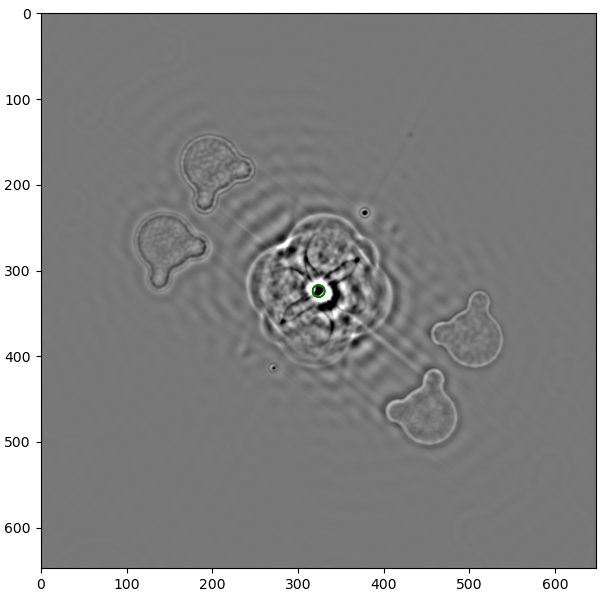

In [ ]:
# How many references do you have?
nr_ref = 4

# Setup coordinates (nr_ref + 1 coordinates, as there is always the object aperture)
support_coordinates = [
    [pos.shape[-2] // 2, pos.shape[-1] // 2, 7] for k in range(nr_ref + 1)
]

# Widget to find the positions and sizes of the different apertures
print(
    "Cover the object & reference apertures for each set of reconstructions that originates from the same reference with circles."
)
print(
    "Optimization: Change one circle parameter, calc phase retrieval image, compare with images reconstructed with old circle parameter. Repeat!"
)

# Create plot
holo = pos * (1 - mask_pixel_smooth)

# Reconstruct
recon = fth.reconstruct(
    fth.propagate(holo, prop_dist * 1e-6, experimental_setup=experimental_setup)
    * np.exp(1j * phase)
)
recon = np.real(recon)

ds = interactive.InteractiveCircleCoordinates(
    recon,
    len(support_coordinates),
    coordinates=support_coordinates.copy(),
)

Text(0.5, 1.0, 'Image with overlayed mask')

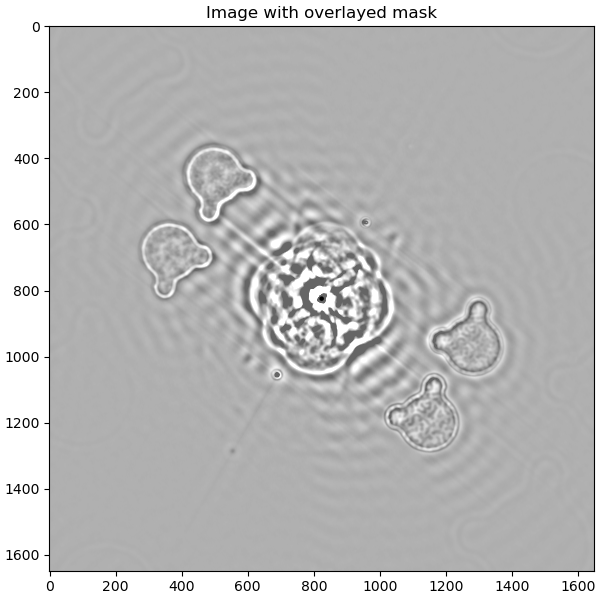

In [38]:
# Take coordinates of circles from widget
support_coordinates = ds.get_params()

# Create supportmask from coordinates
supportmask = mask_lib.create_circle_supportmask(support_coordinates, pos.shape)

# Plot supportmask as overlay
fig, ax = plt.subplots(figsize=(6, 6))
mi, ma = np.percentile(recon, (1, 99))
ax.imshow(recon, vmin=mi, vmax=ma, cmap="gray")
ax.imshow(supportmask, alpha=0.4, cmap="binary")
ax.set_title("Image with overlayed mask")

In [39]:
support_coordinates

[(824.0, 824.0, 7.0),
 (824, 824, 7.0),
 (824, 824, 7.0),
 (824, 824, 7.0),
 (824, 824, 7.0)]

### Option 2: Execute if you want to load an existing support mask created with circle mask widget

In [72]:
def get_supportmask_coordinates(sample):
    """
    Dictionary that stores coordinates of circular support mask apertures
    """

    # Setup dictonary
    support_coord = dict()

    # coordinates
    support_coord["s2402_D1"] = [(969.5, 726.0, 77.0), (1103.0, 457.0, 7.0), (1269.5, 769.5, 7.0), (705.5, 868.0, 7.0), (755.3, 518.0, 7.0), (1024.0, 1024.0, 7.0)]
    support_coord["s2402_D1_new"] = [(976.5, 726.0, 77.0), (1118.0, 460.5, 7.0), (1276.0, 776.5, 7.0), (710.0, 860.5, 7.0), (768.0, 512.0, 7.0), (1024.0, 1024.0, 7.0)]
    support_coord["s2402_D1_cropped"] = [(405.5, 408.0, 39.0), (377.5, 259.0, 4.0), (537.0, 337.0, 4.0), (254.5, 386.0, 5.0), (337.5, 542.0, 4.0), (512.0, 512.0, 4.0)]
    support_coord["CoPd_cropped"] =[(465.0, 412.0, 30.0), (485.5, 303.7, 5.0), (574.5, 398.0, 5.0), (367.5, 360.0, 5.0), (384.5, 488.0, 5.0), (512.0, 512.0, 5.0)]
    support_coord["s2507_B3"] = [(931.0, 822.0, 60.5), (970.5, 607.0, 8.0), (1148.5, 796.0, 8.0), (735.0, 717.5, 8.0), (769.0, 976.0, 8.0), (1024.0, 1024.0, 8.0)]
    support_coord["RT_FGT"] = [(885.0, 678.5, 113.5), (600.5, 919.0, 8.5), (796.0, 1040.5, 8.5), (1024.0, 1024.0, 8.5)]
    support_coord["RT_FGT_1024px"] = [(885.0/2, 678.5/2, 113.5/2), (600.5/2, 919.0/2, 8.5/2), (796.0/2, 1040.5/2, 8.5/2), (1024.0/2, 1024.0/2, 8.5/2)]
    support_coord["T11_crop200"] =[(1024.0, 1024.0, 7.0), (931.0, 1007.0, 27.5), (919.5, 1100.5, 7.0)]
    support_coord["A213.1"] =[(824.0, 824.0, 10.0),(594.0, 959.0, 10),(466.0, 595.5, 39.0),(559.0, 484.5, 40),(451.5, 500.5, 90.0)]
    return support_coord[sample]

In [73]:
# Which supportmask to load? ("s2306a-C1", "s2308a-B1", ...)
sample = "T11_crop200"
sample = "A213.1"

# Get coordinates and create supportmask
support_coordinates = get_supportmask_coordinates(sample)

Cover the object & reference apertures for each set of reconstructions that originates from the same reference with circles.
Optimization: Change one circle parameter, calc phase retrieval image, compare with images reconstructed with old circle parameter. Repeat!
Use circle index slider to change between circles. The active circle is highlighted in red.
Right click to move circle to mouse position!


interactive(children=(FloatRangeSlider(value=(-7.2608207140325565, 6.2362588469665585), description='contrast'…

interactive(children=(IntSlider(value=0, description='index', max=4), Output()), _dom_classes=('widget-interac…

interactive(children=(FloatSlider(value=10.0, description='radius', layout=Layout(width='350px'), max=400.0, s…

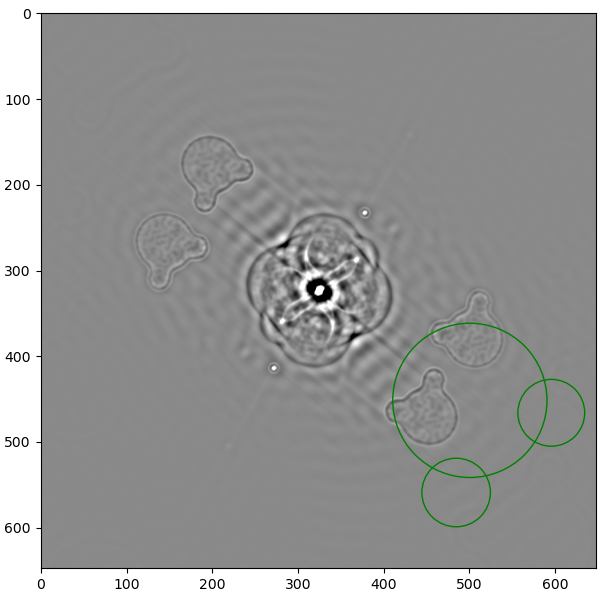

In [74]:
# Widget to find the positions and sizes of the different apertures
print(
    "Cover the object & reference apertures for each set of reconstructions that originates from the same reference with circles."
)
print(
    "Optimization: Change one circle parameter, calc phase retrieval image, compare with images reconstructed with old circle parameter. Repeat!"
)

# Create plot
holo = pos * (1 - mask_pixel_smooth)
ds = interactive.InteractiveCircleCoordinates(
    np.real(fth.reconstruct(holo)),
    len(support_coordinates),
    coordinates=support_coordinates,
)

Text(0.5, 1.0, 'Image with overlayed mask')

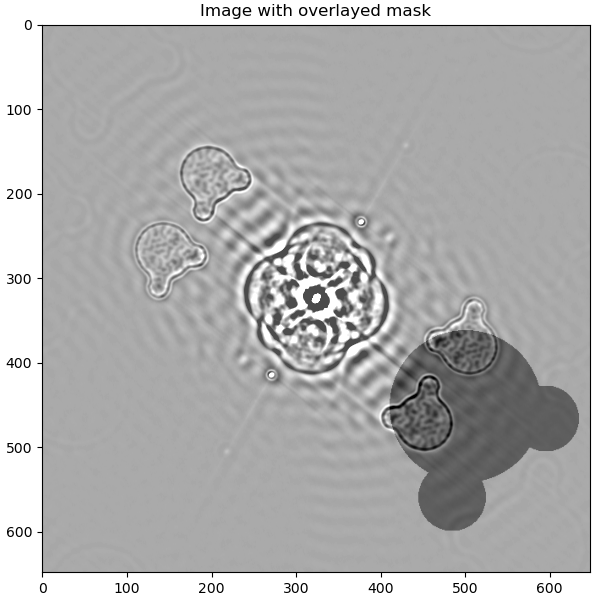

In [75]:
# Take coordinates of circles from widget
support_coordinates = ds.get_params()

# Create supportmask
supportmask = mask_lib.create_circle_supportmask(
    support_coordinates,pos.shape
)
supportmask=1.*(supportmask>0.5)

# What to plot?
tmp = np.real(fth.reconstruct(holo))

# Plot supportmask as overlay
fig, ax = plt.subplots(figsize=(6, 6))
mi, ma = np.percentile(tmp, (1, 99))
ax.imshow(tmp, vmin=mi, vmax=ma, cmap="gray")
ax.imshow(supportmask, alpha=0.3, cmap="binary")
ax.set_title("Image with overlayed mask")

### Take Roi
Choose the reconstructions as the ROI.

1. Zoom into the image and adjust your FOV until you are satisfied.
2. Save the axes coordinates.

interactive(children=(FloatRangeSlider(value=(0.0, 1.0), description='contrast', layout=Layout(width='500px'),…

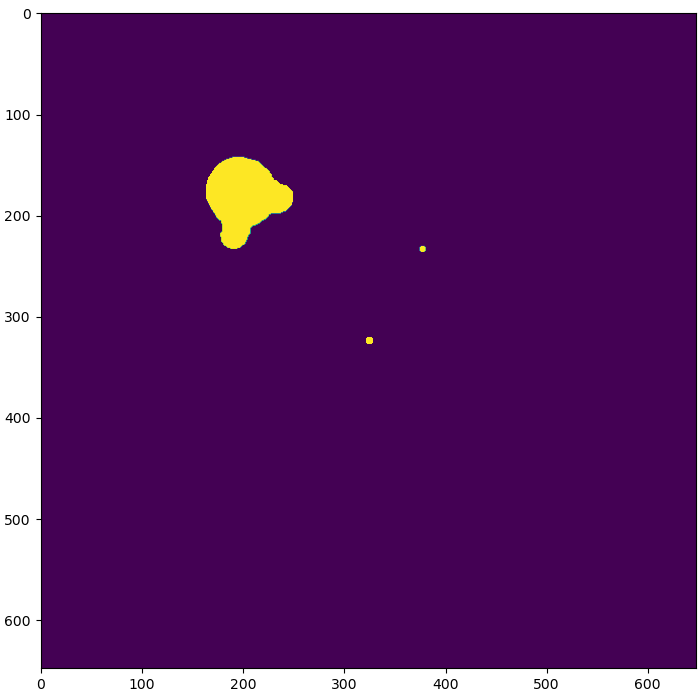

In [78]:
fig, ax = cimshow(supportmask.astype(int))

In [79]:
# Execute to get roi
x1, x2 = ax.get_xlim()
y2, y1 = ax.get_ylim()
roi = np.array([y1, y2, x1, x2]).astype(int)  # ystart, ystop, xstart, xstop
#roi = [350, 604, 390 ,638]
roi_s = np.s_[roi[0] : roi[1], roi[2] : roi[3]]
print(f"Roi Reco:{roi}")

Roi Reco:[138 237 154 253]


interactive(children=(FloatRangeSlider(value=(0.4999999048113823, 8039.894924804884), description='contrast', …

(<Figure size 700x700 with 1 Axes>, <Axes: >)

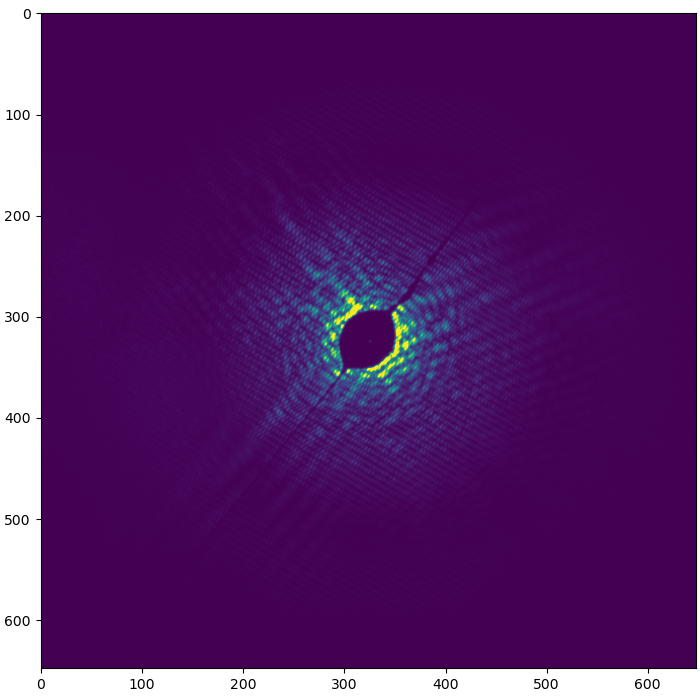

In [80]:
cimshow(im_c)

In [ ]:
import library.Phase_Retrieval as PhR
np.ComplexWarning = RuntimeWarning
import importlib
import library.Phase_Retrieval as PhR
importlib.reload(PhR)

interactive(children=(FloatRangeSlider(value=(0.6431230755226004, 10341.28587058354), description='contrast', …

(<Figure size 700x700 with 1 Axes>, <Axes: >)

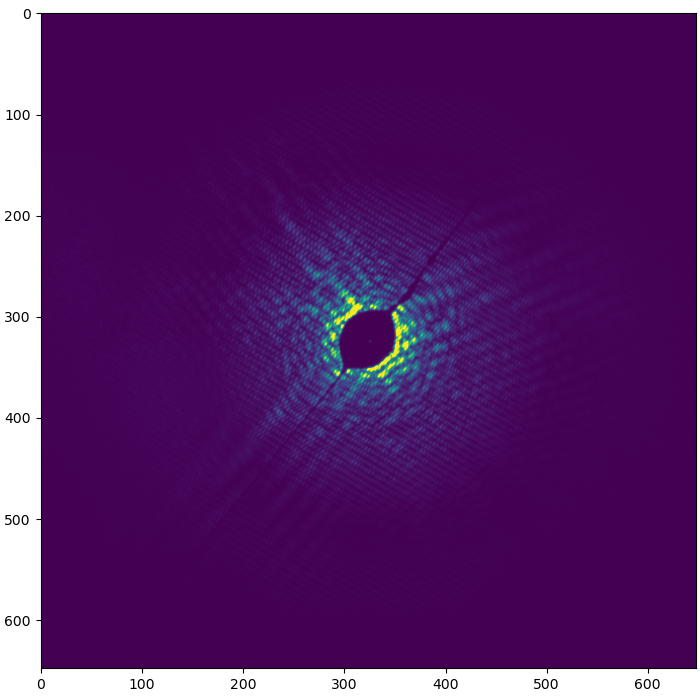

In [98]:
cimshow(pos)

## Do Phase Retrieval

CDI - larger mask
############ -   CDI
--- 0.78 seconds ---
############   -   CDI_pc
--- 3.06 seconds ---
Phase Retrieval Done!
Fine-tuning of reconstruction parameter:


interactive(children=(FloatSlider(value=2.4400000000000004, description='propagation[um]', layout=Layout(width…

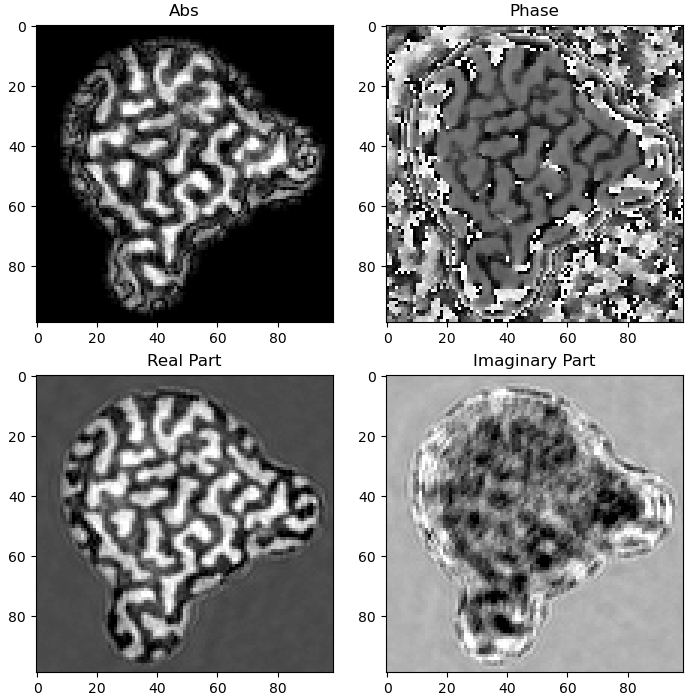

In [97]:

    
# Executes the algorithm
for offset_vmin in [0]:
    for offset in [0]:
        for dilation in [0]:

            
            supportmask=1.*(plt.imread("supportmask_00_2.png")[:,:,0]==1)
            from skimage.draw import disk
            yy,xx=disk(np.array(supportmask.shape)//2,4)
            supportmask[yy,xx]=1
            if dilation>0:
                supportmask=1.*scipy.ndimage.binary_dilation(supportmask, iterations=dilation)


                
            #recon = fth.reconstruct(
            #    fth.propagate(holo, prop_dist * 1e-6, experimental_setup=experimental_setup)
            #    * np.exp(1j * phase)
            #)
            #Startimage = np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(supportmask * recon)))
            Startimage = None
            Startgamma = None
            
            (
                retrieved_p,
                retrieved_n,
                retrieved_p_pc,
                retrieved_n_pc,
                bsmask_p,
                bsmask_n,
                gamma_p,
                gamma_n,
            ) = phase_retrieval(
                pos+offset,
                neg+offset,
                mask_pixel,
                supportmask,
                vmin=offset_vmin,
                Startimage=Startimage,
                Startgamma=Startgamma,
            )
            
            
            # Plotting
            mode = "-"
            print("Fine-tuning of reconstruction parameter:")
            slider_prop, slider_phase, slider_dx, slider_dy = rec.focusCDI(
                retrieved_p_pc,
                retrieved_n_pc,
                roi_s,
                mask=supportmask,
                phase=phase_cdi,
                dx=dx,
                dy=dy,
                prop_dist=prop_dist_cdi,
                experimental_setup=experimental_setup,
                operation=mode,
                max_prop_dist=3,
                scale=(2, 98),
            )

## Reconstruct images from phase retrieval

In [93]:
image.shape

(2048, 2048)

In [ ]:
# New beamstop for CDI recos as phase retrieval of low-q might be insufficient. If phase retrieval worked well
# Try without beamstop: `use_bs = False`
use_bs = False
bs_diam_cdi = 25  # diameter of beamstop


# Create beamstop
if use_bs is True:
    mask_bs_cdi = 1 - mask_lib.circle_mask(
        topo.shape, np.array(topo.shape) / 2, bs_diam_cdi, sigma=4
    )
    mask_bs_cdi = 1 - mask_pixel_smooth.copy()
elif use_bs is False:
    mask_bs_cdi = np.ones(pos.shape)  # if you don't want a beamstop

# Get Recos partial coherence
# Positiv partial coherence
p_pc = cci.reconstruct(
    fth.propagate(
        retrieved_p_pc * mask_bs_cdi,
        prop_dist_cdi * 1e-6,
        experimental_setup=experimental_setup,
    )
)

# Negative partial coherence
n_pc = cci.reconstruct(
    fth.propagate(
        retrieved_n_pc * mask_bs_cdi,
        prop_dist_cdi * 1e-6,
        experimental_setup=experimental_setup,
    )
)

Fine-tuning of reconstruction parameter:


interactive(children=(FloatSlider(value=2.4400000000000004, description='propagation[um]', layout=Layout(width…

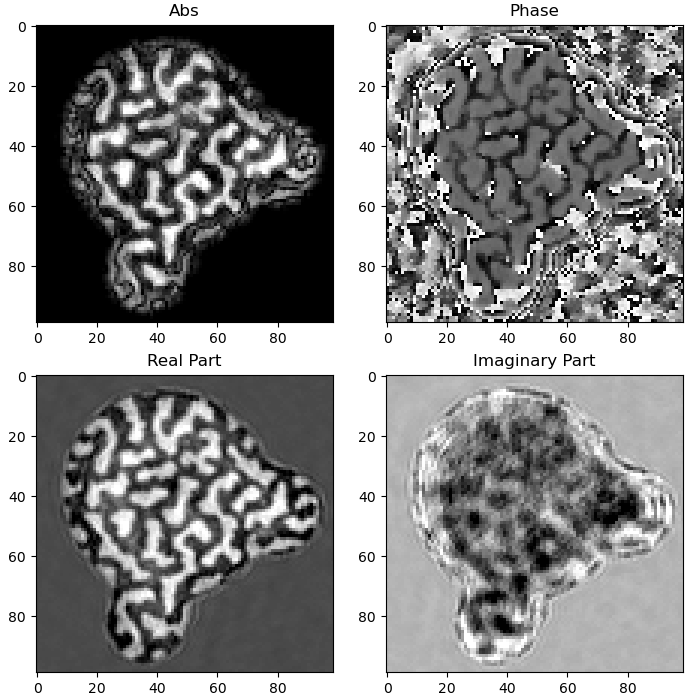

In [90]:
# Plotting
mode = "-"
print("Fine-tuning of reconstruction parameter:")
slider_prop, slider_phase, slider_dx, slider_dy = rec.focusCDI(
    retrieved_p_pc,
    retrieved_n_pc,
    roi_s,
    mask=supportmask,
    phase=phase_cdi,
    dx=dx,
    dy=dy,
    prop_dist=prop_dist_cdi,
    experimental_setup=experimental_setup,
    operation=mode,
    max_prop_dist=3,
    scale=(2, 98),
)

In [85]:
# Get phase from slider
phase_cdi = slider_phase.value
prop_dist_cdi = slider_prop.value

# Reconstruct images with new parameter
p_pc = fth.reconstructCDI(
    fth.propagate(
        retrieved_p_pc * mask_bs_cdi,
        prop_dist_cdi * 1e-6,
        experimental_setup=experimental_setup,
    )
) * np.exp(1j * phase_cdi)

n_pc = fth.reconstructCDI(
    fth.propagate(
        retrieved_n_pc * mask_bs_cdi,
        prop_dist_cdi * 1e-6,
        experimental_setup=experimental_setup,
    )
) * np.exp(1j * phase_cdi)


print("Phase CDI: %s" % phase_cdi)
print("Prop_dist: %s" % prop_dist_cdi)

Phase CDI: -0.6255926535897931
Prop_dist: 2.4400000000000004


Text(0.5, 1.0, 'Neg holo mask')

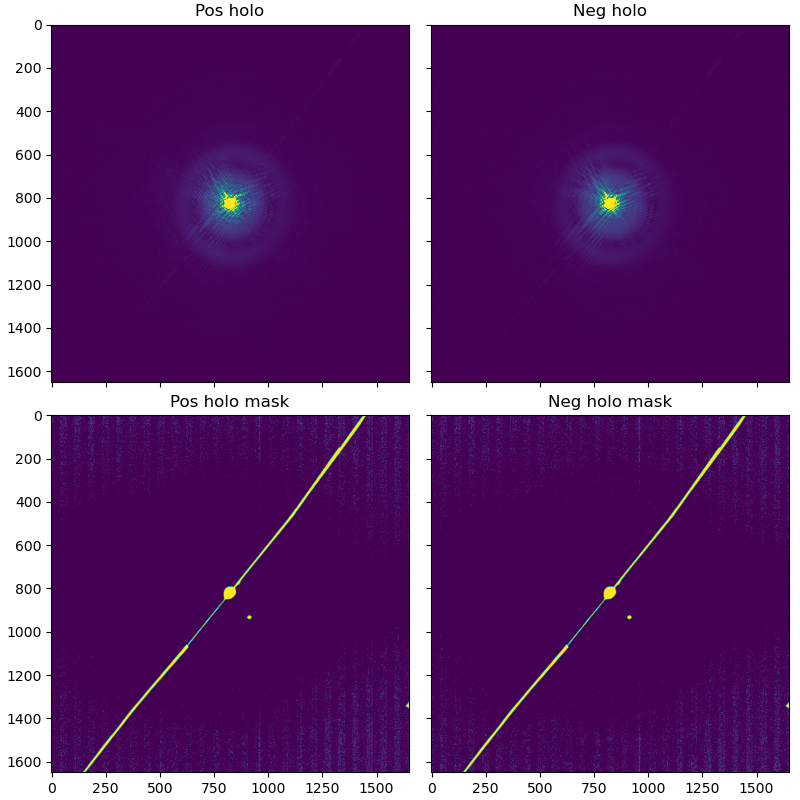

In [53]:
# Confirm that offset subtraction in cdi function works, i.e., only small fraction of hologram is actually masked
fig, ax = plt.subplots(2, 2, figsize=(8, 8), sharex=True, sharey=True)
tmp = np.abs(retrieved_p_pc * mask_bs_cdi)
mi, ma = np.percentile(tmp, [0.1, 99.9])
ax[0, 0].imshow(tmp, vmin=mi, vmax=ma)
ax[0, 0].set_title("Pos holo")

tmp = np.abs(retrieved_n_pc)
mi, ma = np.percentile(tmp, [0.1, 99.9])
ax[0, 1].imshow(tmp, vmin=mi, vmax=ma)
ax[0, 1].set_title("Neg holo")
ax[1, 0].imshow(bsmask_p)
ax[1, 0].set_title("Pos holo mask")
ax[1, 1].imshow(bsmask_n)
ax[1, 1].set_title("Neg holo mask")

interactive(children=(FloatRangeSlider(value=(-4.9518203245160075, 4.441301515937318), description='contrast',…

(<Figure size 700x700 with 1 Axes>, <Axes: >)

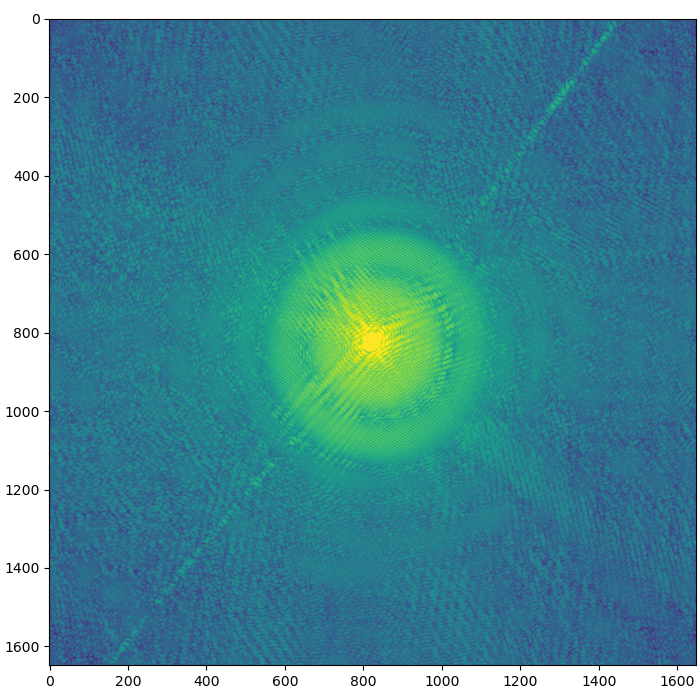

In [55]:
# cimshow(helper.log_clip(np.abs(retrieved_n_pc)))
cimshow(np.log(np.abs(retrieved_n_pc)))

## Save reconstructions

In [60]:
def plot_recon(recon, title, scale_mask=None):
    if scale_mask is None:
        scale_mask = np.ones(recon.shape)

    # Plot
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    fig.suptitle(title)

    tmp = np.real(recon) * scale_mask
    vmin, vmax = np.nanpercentile(tmp[tmp != 0], (1, 99))
    t_im1 = ax[0].imshow(np.real(recon), vmin=vmin, vmax=vmax, cmap="gray")
    ax[0].set_title("Real")
    plt.colorbar(t_im1, ax=ax[0], aspect=50)

    tmp = np.imag(recon) * scale_mask
    vmin, vmax = np.nanpercentile(tmp[tmp != 0], (1, 99))
    t_im2 = ax[1].imshow(np.imag(recon), vmin=vmin, vmax=vmax, cmap="gray")
    ax[1].set_title("Imag")
    plt.colorbar(t_im2, ax=ax[1], aspect=50)


Saving: /asap3/petra3/gpfs/p04/2026/data/11022228/processed/Recon_ImId_2924_RefId_2923_cdi_diff_battistr.png
Now Saving: /asap3/petra3/gpfs/p04/2026/data/11022228/processed/Logs/Data_ImId_2924_RefId_2923_cdi_battistr


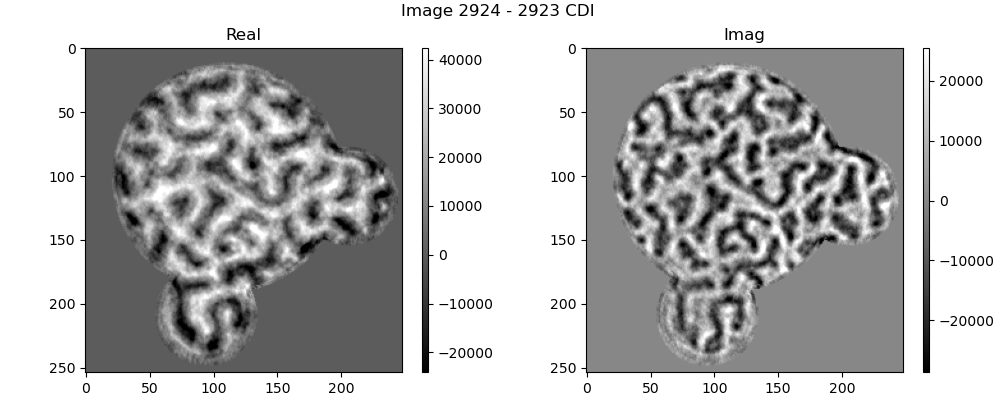

In [61]:
# Saves only real and imaginary part
recon = p_pc - n_pc
#recon = (p_pc - n_pc)  / (p_pc + n_pc)
#recon = np.log(p_pc) - np.log(n_pc)

#footprint = skimage.morphology.disk(4)
shrink_mask = skimage.morphology.erosion(supportmask, footprint)

# Plot
title = get_title(None, im_id, topo_id, CDI=True)
plot_recon(
    recon[roi_cdi_s]*supportmask[roi_cdi_s] , title,# scale_mask=shrink_mask[roi_cdi_s]
)

# Save images
fname = join(
    folder_general,
    "Recon_ImId_%s_RefId_%s_cdi_diff_%s.png" % (im_id, topo_id, USER),
)
print("Saving: %s" % fname)
plt.savefig(fname, bbox_inches="tight", transparent=False)

# Save h5
save_cdi_h5()

# Batch processing CDI

## Define Scan Ids

In [ ]:
plt.close("all")

# Load support mask of which sample?
energy_mode = "A213.1"
support_coordinates = get_supportmask_coordinates(sample)

In [ ]:
# Define the sets for reconstructions. You can make a list or use np.arange
# im_id_set should always have ids of positive helicity holograms,
# topo_id_set those of negative helicity or a hologram of a saturated state

# You can also use nested lists:
# in case topo_id_set = [[id1,id2],id3 it will use the sum hologram
# calculated from [id1,id2] as topo

im_id_set = [2924]#np.arange(873,879)
topo_id_set = [2923]*len(im_id_set)
dark_id_im_set = [2926]* np.ones(len(im_id_set), dtype=int)


use_sub_frame = True

im_frames = None #np.arange(0,len(im_id_set)) which stacks to load for image dataset
topo_frames = [0] #which stack to load from toposet

# In case of single helicity reconstructions, adapt the helicity
helicity = [1]*len(im_id_set)

print("Dynamics Set:  %s" % im_id_set)
print("Reference Set: %s" % topo_id_set)
print("Image index Set: %s" % im_frames)

## Execute Phase Retrieval

## Stack in single im_ids

In [ ]:
# Define the sets for reconstructions. You can make a list or use np.arange
# im_id_set should always have ids of positive helicity holograms,
# topo_id_set those of negative helicity or a hologram of a saturated state

# You can also use nested lists:
# in case topo_id_set = [[id1,id2],id3 it will use the sum hologram
# calculated from [id1,id2] as topo

   

im_id_set = [2924]#np.arange(873,879)
topo_id_set = [2923]*len(im_id_set)
dark_id_im_set = [2926]* np.ones(len(im_id_set), dtype=int)


use_sub_frame = True

im_frames =None#[0]#[-1] #np.arange(0,len(im_id_set)) 
topo_frames = [0]

# In case of single helicity reconstructions, adapt the helicity
helicity = [1]*len(im_id_set)

print("Dynamics Set:  %s" % im_id_set)
print("Reference Set: %s" % topo_id_set)
print("Image index Set: %s" % im_frames)

In [ ]:
dark_all, _ = load_processing(dark_id_im_set[0],file_indices = None)
if isinstance(topo_id_set[0], list):
    print("Using Topo from sum of two helicity holograms")

    topo = (load_processing(topo_id_set[0][0])[0]+load_processing(topo_id_set[0][1])[0]) / 2

    topo_all = topo
else:
    topo_all, _ = load_processing(topo_id_set[0], file_indices=topo_frames)
topo_all = topo_all-dark_all
normalize = False

In [ ]:
shift_c = np.array(topo.shape) / 2 - center

In [ ]:
roi_im_reg=[844, 952, 920, 1032]
roi_im_reg=np.s_[844: 952, 920: 1032]
roi_im_reg=np.s_[:,:]


def worker(image, topo, Norm = True, crop=0):
    # Centering
    shift_c = np.array(topo.shape) / 2 - center
    topo_c = cci.shift_image(topo, shift_c)
    im_c = cci.shift_image(image, shift_c)

    print(crop,shift_c,image.shape,im_c.shape, mask_pixel.shape, topo_c.shape)
    crop=200
    if image.shape[0]==2048:
        roicrop=np.s_[crop:-crop, crop:-crop]
        im_c=im_c[roicrop]
        topo_c=topo_c[roicrop]
    
    print(image.shape,im_c.shape, mask_pixel.shape, topo_c.shape)
    
    if False:
        ## Image registration
        shift = cci.image_registration(
           im_c[roi_im_reg],
            topo_c[roi_im_reg],
         method="dipy",
        )
        #shift = [0, 0]
        print("Relative shift is: %s" % shift)
    
        # Correct relative drift
        topo_c = cci.shift_image(topo_c, shift)
    else:
        shift=[0,0]

    # Create masks
    '''
    # Load polygon mask and shift to manually determined position
    mask = mask_lib.load_poly_masks(
        experimental_setup["binning"] * np.array(image.shape),
        polymasks,
        polygon_names,
    )
    mask = np.round(cci.shift_image(mask, mask_shift))
    # mask = np.zeros(topo_c)

    # Increase/Decrease mask size
    # footprint = skimage.morphology.disk(np.abs(mask_scale))
    # if mask_scale > 0:
    #    mask = skimage.morphology.dilation(mask, footprint) # increase size
    # elif mask_scale < 0:
    #    mask = skimage.morphology.erosion(mask, footprint) # decrease size

    # Create image specific beamstop mask
    mask_im = mask.copy()
    mask_im = mask_im + (im_c > experimental_setup["oversaturation"])
    mask_im[mask_im > 1] = 1

    # Create topo specific beamstop mask
    mask_topo = mask.copy()
    mask_topo = mask_topo + (topo_c > experimental_setup["oversaturation"])

    # Combine both
    mask_pixel = mask_im + mask_topo
    mask_pixel[mask_pixel > 1] = 1

    # Create smooth mask
    footprint = skimage.morphology.disk(4)
    mask_pixel_smooth = skimage.morphology.dilation(mask_pixel, footprint)
    mask_pixel_smooth = gaussian_filter(mask_pixel_smooth, 2)
    ''' 
    if Norm:
        # Get scaling factor and offset
        factor, offset = cci.dyn_factor(
            im_c * (1 - mask_pixel),
            topo_c * (1 - mask_pixel),
            method="correlation",
            verbose=False,
            plot=False,
        )
    else:
        factor = 1
        offset = 0

    # Calculate differences (magnetic) and sums (topographc) contrast holograms.
    # _c: centered, without beamstop, _b: centered, with beamstop
    diff_c = im_c / factor - topo_c - offset
    sum_c = im_c / factor + topo_c - offset

    # Reconstruct
    recon = cci.reconstruct(
        fth.propagate(diff_c, prop_dist * 1e-6, experimental_setup=experimental_setup)
        * np.exp(1j * phase)
    )

    # worker dictionary
    worker_dict = {}
    worker_dict["center"] = center
    worker_dict["topo_c"] = topo_c
    worker_dict["im_c"] = im_c
    worker_dict["recon"] = recon
    worker_dict["factor"] = factor
    worker_dict["offset"] = offset
    worker_dict["shift"] = shift
    worker_dict["diff_c"] = diff_c
    worker_dict["sum_c"] = sum_c
    worker_dict["mask_pixel_smooth"] = mask_pixel_smooth
    worker_dict["mask_pixel"] = mask_pixel

    return worker_dict

interactive(children=(FloatRangeSlider(value=(-0.18999479711055756, 54.63873760223992), description='contrast'…

(<Figure size 700x700 with 1 Axes>, <Axes: >)

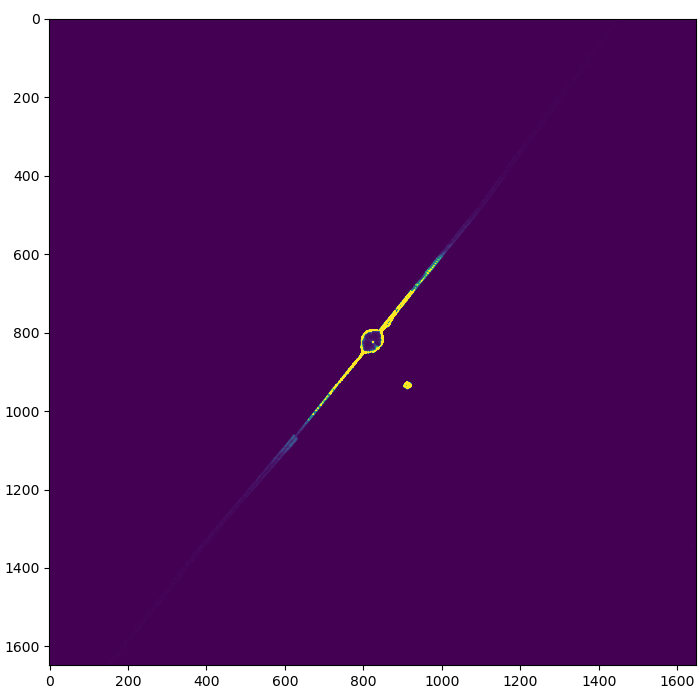

In [ ]:
# Setup phase and propagation for cdi once
phase_cdi = 0
prop_dist_cdi = 0
dx = 0
dy = 0

def phase_retrieval(
    pos, neg, mask_pixel, supportmask, vmin=0, Startimage=None, Startgamma=None
):
    # Prepare Input holograms
    pos2 = pos.copy()
    neg2 = neg.copy()

    mi, _ = np.percentile(pos2[pos2 != 0], [vmin, 99.9])
    pos2 = pos2 - mi
    mi, _ = np.percentile(neg2[neg2 != 0], [vmin, 99.9])
    neg2 = neg2 - mi

    pos2[pos2 < 0] = 0
    neg2[neg2 < 0] = 0
    pos2 = pos2.astype(complex)
    neg2 = neg2.astype(complex)

    bsmask_p = mask_pixel.copy()
    bsmask_p[pos2 <= 0] = 1
    bsmask_n = mask_pixel.copy()
    bsmask_n[neg2 <= 0] = 1

    # Setup start image and startgamma
    if Startimage is None:
        Startimage = np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(supportmask)))
    else:
        Startimage = Startimage.copy()
    if Startgamma is None:
        Startgamma = np.ones(pos.shape) * 1e-6 * 2
        Startgamma[pos.shape[0] // 2, pos.shape[1] // 2] = 0.7
    else:
        Startgamma = Startgamma.copy()

    # Settings for phase retrieval reconstructions
    partial_coherence = True

    # Setup
    retrieved_p = np.zeros(pos2.shape, np.cdouble)
    retrieved_n = np.zeros(pos2.shape, np.cdouble)

    # Algorithms and Inital guess
    plt.rcParams["figure.dpi"] = 100
    print("CDI - larger mask")

    algorithm_list = ["mine", "mine", "mine"]
    Nit_list = [700, 50, 50]  # iterations for algorithm_list

    x = (np.sqrt(np.maximum(pos2, np.zeros(pos2.shape)))[mask_pixel == 0]).flatten()
    y = ((np.abs(Startimage))[mask_pixel == 0]).flatten()
    res = stats.linregress(x, y)
    Startimage -= res.intercept
    Startimage /= res.slope

    average_img = 30
    real_object = False  # always set to False

    if partial_coherence:
        RL_freq = 20
        RL_it = 50

        algorithm_list_pc = ["mine", "ER", "ER"]
        Nit_list_pc = [700, 50, 50]

    # Execute Phase retrieval
    start_time = time.time()
    for i in range(len(Nit_list) // 3):
        print("############ -   CDI")

        # Positive helicity - beta_mode="arctan"
        retrieved_p, Error_diff_p, Error_supp = PhR.PhaseRtrv_GPU(
            diffract=np.sqrt(np.maximum(pos2, np.zeros(pos2.shape))),
            mask=supportmask,
            mode=algorithm_list[3 * i],
            beta_zero=0.5,
            Nit=Nit_list[3 * i],
            beta_mode="arctan",
            plot_every=349,
            Phase=Startimage,
            seed=False,
            real_object=real_object,
            bsmask=bsmask_p,
            average_img=average_img,
            Fourier_last=True,
        )

        # Positive helicity - beta_mode="const"
        retrieved_p, Error_diff_p2, Error_supp = PhR.PhaseRtrv_GPU(
            diffract=np.sqrt(np.maximum(pos2, np.zeros(pos2.shape))),
            mask=supportmask,
            mode=algorithm_list[3 * i + 1],
            beta_zero=0.5,
            Nit=Nit_list[3 * i + 1],
            beta_mode="const",
            plot_every=24,
            Phase=retrieved_p,
            seed=False,
            real_object=real_object,
            bsmask=bsmask_p,
            average_img=average_img,
            Fourier_last=True,
        )

        # Negative helicity - beta_mode="arctan"
        retrieved_n, Error_diff_n2, Error_supp = PhR.PhaseRtrv_GPU(
            diffract=np.sqrt(np.maximum(neg2, np.zeros(neg2.shape))),
            mask=supportmask,
            mode=algorithm_list[3 * i + 2],
            beta_zero=0.5,
            Nit=Nit_list[3 * i + 2],
            beta_mode="const",
            plot_every=24,
            Phase=retrieved_p * np.sqrt(np.sum(neg2) / np.sum(pos2)),
            seed=False,
            real_object=real_object,
            bsmask=bsmask_n,
            average_img=average_img,
            Fourier_last=True,
        )

        print("--- %s seconds ---" % np.round((time.time() - start_time), 2))

        Startimage = retrieved_p.copy()

        # Partial coherence phase retrieval
        if partial_coherence:
            # CDI_PC
            print("############   -   CDI_pc")
            pos3 = (np.abs(retrieved_p) ** 2) * bsmask_p + np.maximum(
                pos2, np.zeros(pos2.shape)
            ) * (1 - bsmask_p)
            neg3 = (np.abs(retrieved_n) ** 2) * bsmask_n + np.maximum(
                neg2, np.zeros(neg2.shape)
            ) * (1 - bsmask_n)

            # retrieve pos image
            (
                retrieved_p_pc,
                Error_diff_p_pc,
                Error_supp,
                gamma_p,
            ) = PhR.PhaseRtrv_with_RL(
                diffract=np.sqrt(pos3),
                mask=supportmask,
                mode=algorithm_list_pc[3 * i],
                beta_zero=0.5,
                Nit=Nit_list_pc[3 * i],
                beta_mode="arctan",
                gamma=Startgamma,
                RL_freq=RL_freq,
                RL_it=RL_it,
                plot_every=349,
                Phase=Startimage,
                seed=False,
                real_object=False,
                bsmask=np.zeros(bsmask_p.shape),
                average_img=average_img,
                Fourier_last=True,
            )

            (
                retrieved_p_pc,
                Error_diff_p_pc2,
                Error_supp,
                gamma_p,
            ) = PhR.PhaseRtrv_with_RL(
                diffract=np.sqrt(pos3),
                mask=supportmask,
                mode=algorithm_list[3 * i + 1],
                beta_zero=0.5,
                Nit=Nit_list_pc[3 * i + 1],
                beta_mode="const",
                gamma=gamma_p,
                RL_freq=RL_freq,
                RL_it=RL_it,
                plot_every=24,
                Phase=retrieved_p_pc,
                real_object=False,
                bsmask=np.zeros(bsmask_p.shape),
                average_img=average_img,
                Fourier_last=True,
            )
            (
                retrieved_n_pc,
                Error_diff_n_pc2,
                Error_supp,
                gamma_n,
            ) = PhR.PhaseRtrv_with_RL(
                diffract=np.sqrt(neg3),
                mask=supportmask,
                mode=algorithm_list[3 * i + 2],
                beta_zero=0.5,
                Nit=Nit_list_pc[3 * i + 2],
                beta_mode="const",
                gamma=gamma_p,
                RL_freq=RL_freq,
                RL_it=RL_it,
                plot_every=24,
                Phase=retrieved_p_pc * np.sqrt(np.sum(neg2) / np.sum(pos2)),
                real_object=False,
                bsmask=np.zeros(bsmask_n.shape),
                average_img=average_img,
                Fourier_last=True,
            )

            print("--- %s seconds ---" % np.round((time.time() - start_time), 2))

            Startimage = retrieved_p_pc.copy()
            Startgamma = gamma_p.copy()

    print("Phase Retrieval Done!")

    return (
        retrieved_p,
        retrieved_n,
        retrieved_p_pc,
        retrieved_n_pc,
        bsmask_p,
        bsmask_n,
        gamma_p,
        gamma_n,
    )

In [ ]:
# Ugly Automatic processing of image stacks
recons_name = []  # for gifs
fth_reco_name = []
images = []
energy_list = []
prop_dist_cdi=3
for it, im_id in enumerate(tqdm(im_id_set,desc="im_ids")):
    for stack in tqdm(range(get_marana_filenames(im_id, file_indices = None).shape[0]),desc="marana files"):
        if stack ==0 or stack>20:
            
            # Load energy and add to experimental setup
            experimental_setup["energy"] = load_key(im_id, "/scan/instrument/collection/mono")
            experimental_setup["lambda"] = helper.photon_energy_wavelength(
                experimental_setup["energy"], input_unit="eV"
            )
            
            # Load images
            #image, _ = load_processing(im_id, file_indices=np.arange(4)+4*stack)
            image, _ = load_processing(im_id, file_indices=[stack])
        
            # Load dark
            dark_id = dark_id_im_set[it]
            if dark_id is not None:
                dark = dark_all.copy()
                #, _ = load_processing(dark_id, crop=None)
                image = image - dark
        
            # Get topo
            topo_id = topo_id_set[it]
        
            # Load data
            if isinstance(topo_id_set[0], list):
                topo_id = topo_id[0]
            else:
                print(f"Loading imageId: %04d, topoId: %04d" % (im_id, topo_id))
            topo = topo_all.copy()
        
            # Process images
            worker_dict = worker(image, topo, Norm=True)
        
            # Save topo hologram
            #save_topo_holo(worker_dict["sum_c"], im_id, topo_id)   
            
            # Reconstruct
            recon = worker_dict["recon"]
            
            # Plot
            #title = get_title("magnet_A", im_id, topo_id,  Framenumber= stack)
            #plot_recon(recon[roi_cdi_s], title)
        
            if use_sub_frame:
                # Save images
                fname = join(
                folder_general,
                "Recon_ImId_%04d_RefId_%s_fth_diff_stack_%s_frame_%s.png" % (im_id, topo_id, USER, it),
                )
            else: 
                # Save images
                fname = join(
                    folder_general,
                    "Recon_ImId_%04d_RefId_%s_fth_diff_stack_%s.png" % (im_id, topo_id, USER),
                )
            #print("Saving: %s" % fname)
            #plt.savefig(fname, bbox_inches="tight", transparent=False)
            #fth_reco_name.append(fname)
            # Optional: Save hdf5 file of fth data
            #save_fth_h5()
        
            ################ CDI ###############
            # Create pos and neg helicity set
            pos = (worker_dict["sum_c"] + worker_dict["diff_c"])/2
            neg = (worker_dict["sum_c"] - worker_dict["diff_c"])/2
        
            # Create mask pixel
            mask_pixel = worker_dict["mask_pixel"]
        
            # Create supportmask from coordinates
            supportmask = mask_lib.create_circle_supportmask(support_coordinates, pos.shape)
            supportmask=1.*(supportmask>0.5)
            supportmask=np.load("supportmask.npy")
            
            if stack == 0:
                # Do phase retrieval
                (
                    retrieved_p,
                    retrieved_n,
                    retrieved_p_pc,
                    retrieved_n_pc,
                    bsmask_p,
                    bsmask_n,
                    gamma_p,
                    gamma_n,
                ) = phase_retrieval(pos, neg, mask_pixel, supportmask, vmin = offset_vmin, Startimage=Startimage, Startgamma=Startgamma)
                retrieved_p_pc_start, gamma_p_start, retrieved_n_pc_start, gamma_n_start = retrieved_p_pc, gamma_p, retrieved_n_pc, gamma_n
            elif stack>0:
                # Do phase retrieval
                offset_vmin = 0.5
                mi, _ = np.percentile(pos[pos != 0], [offset_vmin, 99.9])
                pos3 = pos - mi
                (
                    retrieved_p_pc,
                    Error_diff_p_pc2,
                    Error_supp,
                    gamma_p,
                ) = PhR.PhaseRtrv_with_RL(
                    diffract=np.sqrt(np.maximum(pos3, np.zeros(pos3.shape))),
                    mask=supportmask,
                    mode="mine",
                    beta_zero=0.5,
                    Nit=10,
                    beta_mode="const",
                    gamma=gamma_n_start.copy(),
                    RL_freq=20,
                    RL_it=50,
                    Phase=retrieved_n_pc_start.copy(),
                    real_object=False,
                    bsmask=mask_pixel.astype(int),
                    average_img=30,
                    Fourier_last=True,
                )


            
            # Get Recos partial coherence
            # Positiv partial coherence
            p_pc = fth.reconstructCDI(
                fth.propagate(
                    retrieved_p_pc * mask_bs_cdi,
                    prop_dist_cdi * 1e-6,
                    experimental_setup=experimental_setup,
                )
            )
            # Negative partial coherence
            n_pc = fth.reconstructCDI(
                fth.propagate(
                    retrieved_n_pc * mask_bs_cdi,
                    prop_dist_cdi * 1e-6,
                    experimental_setup=experimental_setup,
                )
            )
        
            ##### Calc reco and optimze contrast
            recon = helicity[it] * (p_pc - n_pc)
            #_, phase_cdi = optimize_phase_contrast(recon, supportmask, method="contrast")
            #phase_cdi = 0
            recon = recon * np.exp(1j * phase_cdi)
            print("Phase is:", np.round(phase_cdi, 2))
            ########
        
            # Plot
            #try:
            #    title = get_title("magnet_A", im_id, topo_id, CDI=True,Framenumber=stack)
            #except:
            title = get_title(None, im_id, topo_id, CDI=True,Framenumber=stack)
            plot_recon(recon[roi_s], title)
            images.append(recon[roi_s])
            
            if use_sub_frame:
                fname = join(
                folder_general,
                "Recon_ImId_%04d_RefId_%s_cdi_stack_%s_frame_%s.png" % (im_id, topo_id, USER, stack),
                )
            else:
                fname = join(
                    folder_general,
                    "Recon_ImId_%04d_RefId_%s_cdi_stack_%s.png" % (im_id, topo_id, USER),
                )
        
            print("Saving: %s" % fname)
            plt.savefig(fname, bbox_inches="tight", transparent=False, dpi=300)
            recons_name.append(fname)
        
            # Save files as h5
            save_cdi_h5()
            print(" ")
print("CDI stack processing finished")

im_ids:   0%|          | 0/1 [00:00<?, ?it/s]

marana files:   0%|          | 0/101 [00:00<?, ?it/s]

['/asap3/petra3/gpfs/p04/2026/data/11022228/raw/2602_orbitronics_02924/marana/2602_orbitronics_02924_000000.nx']


  0%|          | 0/1 [00:00<?, ?it/s]

Loading imageId: 2924, topoId: 2923
0 [  3. 133.] (2048, 2048) (2048, 2048) (1648, 1648) (2048, 2048)
(2048, 2048) (1648, 1648) (1648, 1648) (1648, 1648)
CDI - larger mask
############ -   CDI
--- 2.61 seconds ---
############   -   CDI_pc
--- 11.36 seconds ---
Phase Retrieval Done!
Phase is: 0.0
Saving: /asap3/petra3/gpfs/p04/2026/data/11022228/processed/Recon_ImId_2924_RefId_2923_cdi_stack_battistr_frame_0.png
Now Saving: /asap3/petra3/gpfs/p04/2026/data/11022228/processed/Logs/Data_ImId_2924_RefId_2923_cdi_battistr
 
['/asap3/petra3/gpfs/p04/2026/data/11022228/raw/2602_orbitronics_02924/marana/2602_orbitronics_02924_000021.nx']


...

Loading imageId: 2924, topoId: 2923
0 [  3. 133.] (2048, 2048) (2048, 2048) (1648, 1648) (2048, 2048)
(2048, 2048) (1648, 1648) (1648, 1648) (1648, 1648)
Phase is: 0.0
Saving: /asap3/petra3/gpfs/p04/2026/data/11022228/processed/Recon_ImId_2924_RefId_2923_cdi_stack_battistr_frame_32.png
Now Saving: /asap3/petra3/gpfs/p04/2026/data/11022228/processed/Logs/Data_ImId_2924_RefId_2923_cdi_battistr
 
['/asap3/petra3/gpfs/p04/2026/data/11022228/raw/2602_orbitronics_02924/marana/2602_orbitronics_02924_000033.nx']


  0%|          | 0/1 [00:00<?, ?it/s]

Loading imageId: 2924, topoId: 2923
0 [  3. 133.] (2048, 2048) (2048, 2048) (1648, 1648) (2048, 2048)
(2048, 2048) (1648, 1648) (1648, 1648) (1648, 1648)
Phase is: 0.0
Saving: /asap3/petra3/gpfs/p04/2026/data/11022228/processed/Recon_ImId_2924_RefId_2923_cdi_stack_battistr_frame_33.png
Now Saving: /asap3/petra3/gpfs/p04/2026/data/11022228/processed/Logs/Data_ImId_2924_RefId_2923_cdi_battistr
 
['/asap3/petra3/gpfs/p04/2026/data/11022228/raw/2602_orbitronics_02924/marana/2602_orbitronics_02924_000034.nx']


  0%|          | 0/1 [00:00<?, ?it/s]

Loading imageId: 2924, topoId: 2923
0 [  3. 133.] (2048, 2048) (2048, 2048) (1648, 1648) (2048, 2048)
(2048, 2048) (1648, 1648) (1648, 1648) (1648, 1648)


In [ ]:
helper.create_gif(recons_name,join(BASEFOLDER, "processed",f"Scan_{im_id}_{USER}.gif"),fps = 3,loop = 0)

interactive(children=(FloatRangeSlider(value=(0.0, 1.0), description='contrast', layout=Layout(width='500px'),…

(<Figure size 700x700 with 1 Axes>, <Axes: >)

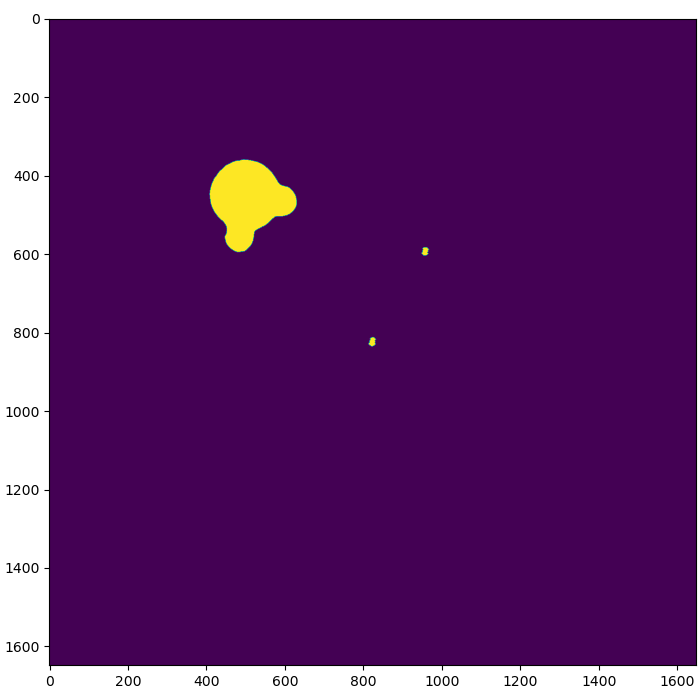

In [147]:
p_pc = fth.reconstructCDI(
    fth.propagate(
        retrieved_p_pc * mask_bs_cdi,
        prop_dist_cdi * 1e-6,
        experimental_setup=experimental_setup,
    )
) * np.exp(1j * phase_cdi)
p_pc=1.*(p_pc>1e5)
supportmask=p_pc.copy()
supportmask=scipy.ndimage.binary_dilation(supportmask, iterations=3)

np.save("supportmask.npy", supportmask)

cimshow(supportmask)

Fine-tuning of reconstruction parameter:


interactive(children=(FloatSlider(value=3.0, description='propagation[um]', layout=Layout(width='90%'), max=3.…

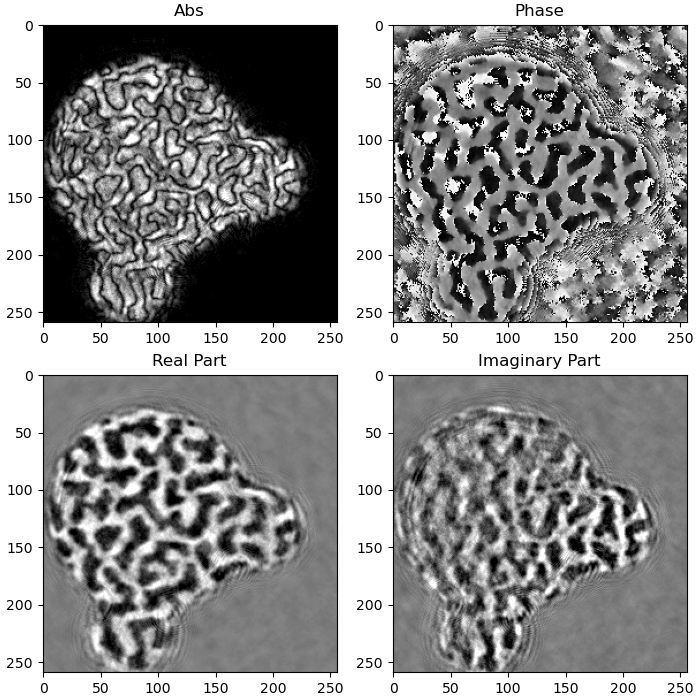

In [137]:
# Plotting
plt.close("all")
mode = "-"
print("Fine-tuning of reconstruction parameter:")
slider_prop, slider_phase, slider_dx, slider_dy = rec.focusCDI(
    retrieved_p_pc,
    retrieved_n_pc,
    roi_s,
    mask=supportmask,
    phase=phase_cdi,
    dx=dx,
    dy=dy,
    prop_dist=prop_dist_cdi,
    experimental_setup=experimental_setup,
    operation=mode,
    max_prop_dist=3,
    scale=(2, 98),
)


In [ ]:
plt.close("all")

In [92]:
mask_pixel.shape, im_c.shape, topo_c.shape

((1648, 1648), (1648, 1648), (1648, 1648))

In [83]:
im_c.shape

(1648, 1648)